### Jupyter - ułatwienia w pracy, pisaniu kodu

**Automatyczne uzupełnianie kodu (Tab)** <BR>
* Wpisz początek funkcji/zmiennej i naciśnij Tab

**Podpowiedzi argumentów funkcji (Shift + Tab)**
* Wpisz nazwę funkcji i otwórz nawias, a następnie naciśnij Shift + Tab
* Jeśli chcesz więcej szczegółów, naciśnij Shift + Tab większą liczbę razy.
    
**Wywołanie dokumentacji (?)**
* Dodaj ? przed lub po funkcji, aby zobaczyć dokumentację
    
**Pełne podświetlanie składni i podpowiedzi (Jupyter Lab)**
    
* pip install jupyterlab-lsp python-lsp-server

## Drugi przykład analizy
### Wykonamy krok po kroku kolejne kroki związane z:

1. **Importem danych**
2. **Zrozumieniem danych**
3. **Czyszczeniem danych**
4. **Budową modelu**
5. **Oceną modeu**
6. **Interpretacją modelu**

In [49]:
#Dodatkowe "ułatwienia" w ustawieniach wyświetlania i obsłudze ostrzeżeń

# Wyłączenie ramki wyświetlania (jeśli nam przeszkadza)
from IPython.display import display, HTML
display(HTML("<style>.output_scroll { height: auto !important; }</style>"))

# Wyłączenie ostrzeżeń dla analizy k-średnich
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)



In [50]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [51]:
import os
print(os.getcwd())  # Wyświetli aktualny katalog roboczy

c:\Users\XYZ


### Poniżej lista często wykorzystywanych bibliotek, ich rolę będziemy poznawali krok po kroku

In [52]:
# Struktury danych, podstawowe operacje na danych
import pandas as pd
import numpy as np

# wykresy
import matplotlib.pyplot as plt
import seaborn as sns

# Uzupełnianie braków danych
from sklearn.impute import (SimpleImputer,KNNImputer)

# Wartosci odstające
from feature_engine.outliers import Winsorizer

# Skalowanie wartości zmiennych
from sklearn.preprocessing import MinMaxScaler

# Budowa modelu k-średnich
from sklearn.cluster import KMeans

# wartość początkowa dla generatora liczb losowych
seed=1

### Dodatkowe biblioteki potrzebne do analizy

In [53]:
# Analiza hierarchiczna
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering

# Do wizualizacji skupień
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Metoda GMM
from sklearn.mixture import GaussianMixture

# Sieci neuronowe Kohonena
%pip install minisom
from minisom import MiniSom

# metoda DBSCAN
from sklearn.cluster import DBSCAN

Note: you may need to restart the kernel to use updated packages.


In [54]:
# Instalujemy bibliotekę dla sieci neuronowych Kohonena
!pip install minisom

## Co zawiera zbiór i po co robmy analizę?

**Zbiór zawiera zestaw produktów spożywczych opisanych przez zawartości różnych substancji, typu białko, węglowodany, mikroelemnty, witaminy itp. <BR>
Celem analizy jest pogrupowanie produktów spożywczych w zależności od zawartości substancji odżywczych.**

### Import danych i pierwsze pytania do danych

1. Jaka jest struktura danych? 
2. Ile jest przypadków? Ile wierszy?
3. Co one oznaczają?
4. Jakie są typy kolumn w ramce danych?
5. Jaka jest liczba różnych wartości?

In [55]:
# Import danych z pliku xlsx do obiektu food_df - ramki danych  
# header=1 (drugi wiersz pliku zostanie wykorzystany jako nazwy zmiennych)
# index_col=0 (wartości w pierwszej kolumnie zostaną użyte jako indeksy poszczególnych obiektów).
# Import danych z pliku xlsx do obiektu food_df
food_df = pd.read_excel(r'C:\Users\XYZ\OneDrive\Pulpit\projects\projects_learning_AGH\data_AGH\skladniki_simple.xlsx', header=1, index_col=0, engine='openpyxl')

# Sprawdzenie wczytanych danych
print(food_df.shape)
food_df.head()

(69, 14)


,ID,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
Butter,1001,717.0,0.85,81.11,0.06,24.0,NaN,0.02,684.0,0.005,0.0,NaN,0.0,0.034
"Cheese, cheddar",1009,404.0,22.87,33.31,3.09,710.0,455.0,0.14,330.0,0.029,0.0,0.6,0.0,0.428
"Cheese, cream",1017,350.0,6.15,34.44,5.52,97.0,107.0,0.11,308.0,0.023,0.0,NaN,0.0,0.230
"Cheese, feta",1019,264.0,14.21,21.28,4.09,493.0,337.0,0.65,125.0,0.154,0.0,0.4,0.0,0.844
Mozzarella,1026,300.0,22.17,22.35,2.19,505.0,354.0,0.44,179.0,0.030,0.0,0.4,0.0,0.283


In [56]:
# Jaka jest liczba przypadków? Jaka jest liczba zmiennych?
print(food_df.shape)

(69, 14)


In [57]:
# Pokazuje wszystkie kolumny zbioru podczas podglądu
pd.set_option("display.max_columns", None) 

# Wyświetlenie kilku pierwszych wierszy
food_df.head(10)

,ID,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
Butter,1001,717.0,0.85,81.11,0.06,24.0,NaN,0.02,684.0,0.005,0.0,NaN,0.0,0.034
"Cheese, cheddar",1009,404.0,22.87,33.31,3.09,710.0,455.0,0.14,330.0,0.029,0.0,0.6,0.0,0.428
"Cheese, cream",1017,350.0,6.15,34.44,5.52,97.0,107.0,0.11,308.0,0.023,0.0,NaN,0.0,0.230
"Cheese, feta",1019,264.0,14.21,21.28,4.09,493.0,337.0,0.65,125.0,0.154,0.0,0.4,0.0,0.844
Mozzarella,1026,300.0,22.17,22.35,2.19,505.0,354.0,0.44,179.0,0.030,0.0,0.4,0.0,0.283
Parmesan,1032,420.0,28.42,27.84,13.91,853.0,627.0,0.49,262.0,0.026,0.0,0.5,0.0,0.358
Cream,1049,123.0,3.13,10.39,4.73,107.0,95.0,0.05,97.0,0.030,0.9,NaN,0.0,0.194
Milk,1078,64.0,3.28,3.66,4.65,119.0,93.0,0.05,33.0,0.038,1.5,NaN,NaN,NaN
Yogurt,1116,61.0,3.47,3.25,4.66,121.0,95.0,0.05,27.0,0.029,0.5,0.1,0.0,0.142
Egg,1128,196.0,13.61,14.84,0.83,62.0,215.0,1.89,219.0,0.044,0.0,2.2,0.0,0.495


In [58]:
# Podstawowe sprawdzenie typów danych
food_df.dtypes

ID                    int64
Energia (kcal)      float64
Białko (g)          float64
Tłuszcz (g)         float64
Węglowodany (g)     float64
Wapń (mg)           float64
Fosfor (mg)         float64
Żelazo (mg)         float64
Witamina A (ug)     float64
Witamina B1 (mg)    float64
Witamina C (mg)     float64
Witamina D (ug)     float64
Błonnik (g)         float64
Witamina B2 (mg)    float64
dtype: object

In [59]:
# Sprawdzenie liczby unikalnych wartości
food_df.nunique()

ID                  69
Energia (kcal)      62
Białko (g)          67
Tłuszcz (g)         60
Węglowodany (g)     56
Wapń (mg)           58
Fosfor (mg)         57
Żelazo (mg)         57
Witamina A (ug)     37
Witamina B1 (mg)    54
Witamina C (mg)     32
Witamina D (ug)     16
Błonnik (g)         23
Witamina B2 (mg)    50
dtype: int64

### Pierwsza decyzja

1. Rola zmiennych w analizie

In [60]:
# Określ rolę zmiennych w analizie 
id_variable = ['ID']
predictors = [var for var in food_df.columns if var not in id_variable]

In [61]:
print(predictors)

['Energia (kcal)', 'Białko (g)', 'Tłuszcz (g)', 'Węglowodany (g)', 'Wapń (mg)', 'Fosfor (mg)', 'Żelazo (mg)', 'Witamina A (ug)', 'Witamina B1 (mg)', 'Witamina C (mg)', 'Witamina D (ug)', 'Błonnik (g)', 'Witamina B2 (mg)']


**Zauważmy, że w tej sytuacji nie mamy "rzeczywistego" podziału na grupy! Jest to sytuacja typowa w tego rodzaju analizach.**

### Ocena jakości zbioru danych

1. Raport braków danych
2. Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
3. Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
4. Oczena pod kątem wartości odstających i kategorii o małej liczności

In [62]:
# Tworzenie raportu braków danych
missing_report = pd.DataFrame({
    'Liczba braków': food_df.isnull().sum(),
    'Procent braków': (food_df.isnull().mean() * 100).round(2)
})

# Wyświetlenie raportu braków danych
print(missing_report)

                  Liczba braków  Procent braków
ID                            0            0.00
Energia (kcal)                0            0.00
Białko (g)                    0            0.00
Tłuszcz (g)                   0            0.00
Węglowodany (g)               0            0.00
Wapń (mg)                     2            2.90
Fosfor (mg)                   9           13.04
Żelazo (mg)                   0            0.00
Witamina A (ug)               6            8.70
Witamina B1 (mg)              5            7.25
Witamina C (mg)               5            7.25
Witamina D (ug)              22           31.88
Błonnik (g)                  14           20.29
Witamina B2 (mg)             15           21.74


### Tym razem mamy braki danych w zmiennych

**Przekonajmy się jeszcze jak to wygląda w obrębie przypadków**

In [63]:
# Analiza braków danych w obrębie wierszy
null_row_report = food_df[predictors].isnull().mean(axis=1).sort_values(ascending=False)

# Wyświetl pierwszych 10 rekordów
null_row_report.head(10)

Cocoa butter                             0.538462
Chocolate ice cream                      0.538462
ESTLE, CRUNCH Bar and Dessert Topping    0.538462
Oil                                      0.461538
HERSHEY, KIT KAT BIG KAT Bar             0.384615
Veal                                     0.384615
Olive                                    0.307692
Chocolate                                0.307692
Tuna                                     0.230769
Lamb                                     0.230769
dtype: float64

### Pierwsza ingerencja w dane

In [64]:
# usuwamy z analizy przypadki z odsetkiem braków danych powyżej 40% ich analiza mogłaby być obciążająca dla uzyskanych wyników
food_df = food_df[food_df[predictors].isnull().mean(axis=1) <= 0.4]

In [65]:
# Ponowny raport braków danych po uzunięciu przypadków
# Tworzenie raportu braków danych
missing_report = pd.DataFrame({
    'Liczba braków': food_df.isnull().sum(),
    'Procent braków': (food_df.isnull().mean() * 100).round(2)
})

# Wyświetlenie raportu braków danych
print(missing_report)

                  Liczba braków  Procent braków
ID                            0            0.00
Energia (kcal)                0            0.00
Białko (g)                    0            0.00
Tłuszcz (g)                   0            0.00
Węglowodany (g)               0            0.00
Wapń (mg)                     0            0.00
Fosfor (mg)                   5            7.69
Żelazo (mg)                   0            0.00
Witamina A (ug)               2            3.08
Witamina B1 (mg)              1            1.54
Witamina C (mg)               3            4.62
Witamina D (ug)              18           27.69
Błonnik (g)                  11           16.92
Witamina B2 (mg)             11           16.92


### Wybór techniki uzupełnienia braków danych w dużej mierze zależy od procenta braków danych

1. Dla zmiennych z niewielkim odsetkiem braków wystarczy prosta metoda uzupełniania oparta na medianie (zatępujemy wartością środkową)
2. Dla zmiennych z odsetkiem braków powyżej 5% użyjemy bardziej wyrafinowanej metody opartej na przewidywaniu braków danych

In [66]:
# Dodatkowe dwie listy zmiennych z brakami danych w zależności od odsetka braków danych podejmiemy inne czynności
missing_over_5 = [var for var in predictors if
                   food_df[var].isnull().mean()>=0.05]

missing_below_5 = [var for var in predictors if food_df[var].isnull().mean()>0
                   and var not in missing_over_5 ]

In [67]:
print(missing_over_5)

['Fosfor (mg)', 'Witamina D (ug)', 'Błonnik (g)', 'Witamina B2 (mg)']


In [68]:
print(missing_below_5)

['Witamina A (ug)', 'Witamina B1 (mg)', 'Witamina C (mg)']


### Badamy rozkłady zmiennych

1. Liczba unikalnych wartości
2. Analiza rozkładów zmienne ilościowe - histogramy, wykres ramkowy, statystyki
3. Analiza rozkładów zmienne jakościowe - histogramy, tabela liczności
4. Oczena pod kątem wartości odstających i kategorii o małej liczności

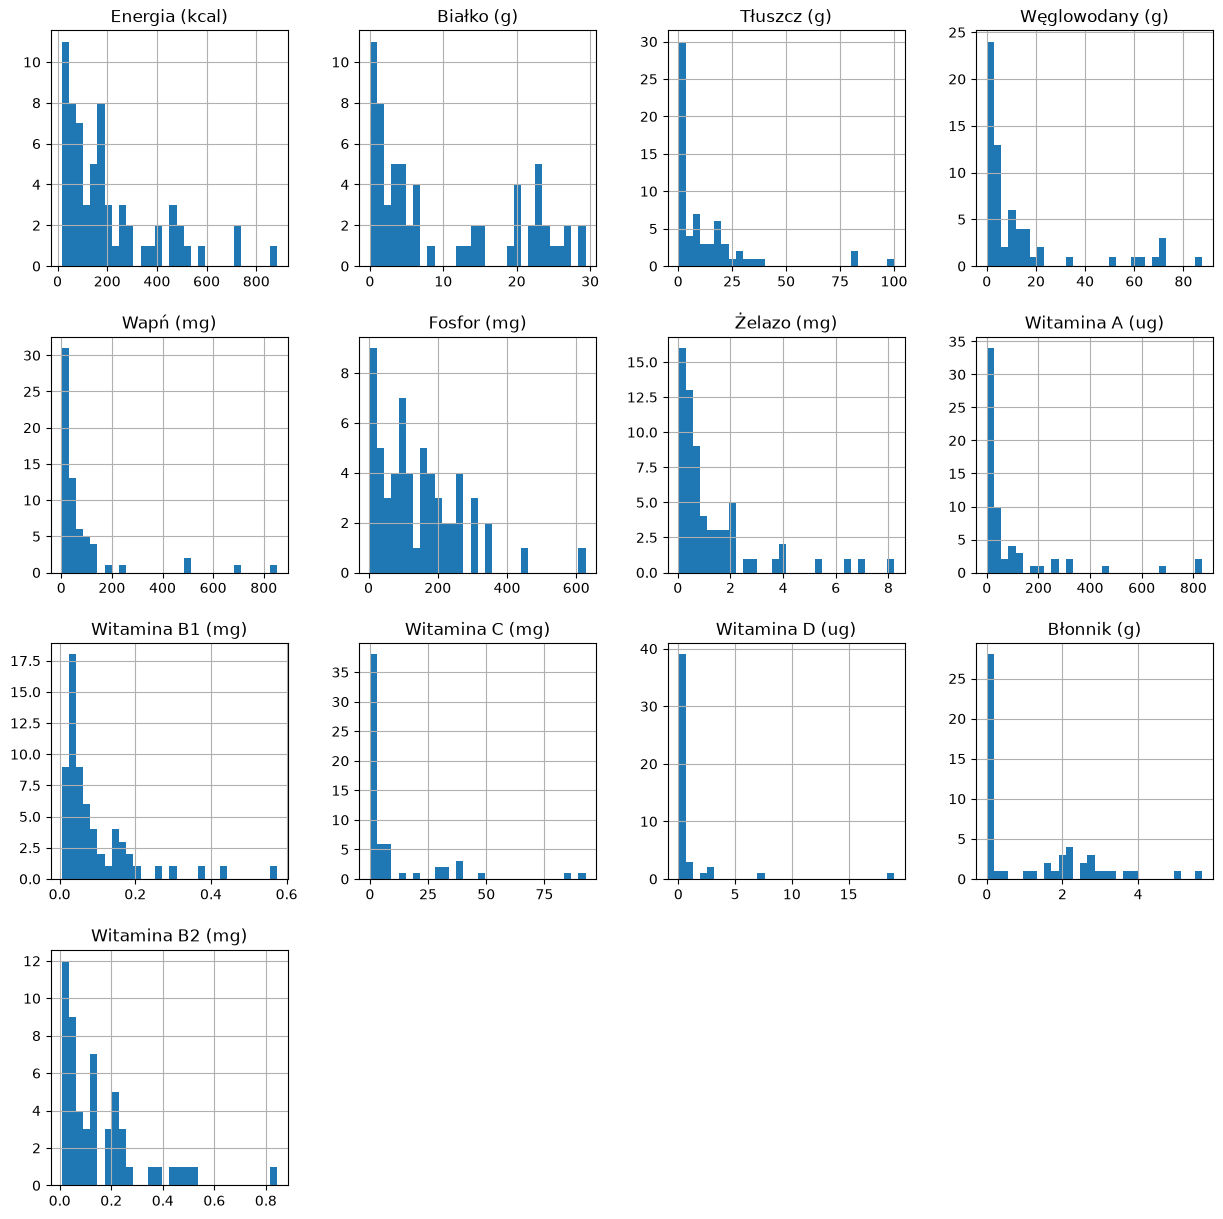

In [69]:
# Analiza rozkładów zmiennych
# Histogramy dla zmiennych ilościowych

food_df[predictors].hist(bins=30, figsize=(15,15))
plt.show()

In [70]:

def plot_box_strip(df, variables, hue=None):
    """
    Tworzy wykresy pudełkowe z nakładającymi się wykresami strip dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn dla zmiennych ilościowych
    - hue: opcjonalna zmienna grupująca (kategoryczna)
    """
    for var in variables:
        plt.figure(figsize=(8, 6))
        
        # Wykres pudełkowy
        sns.boxplot(data=df, y=var, x=hue, fliersize=0, color='green')

        # Wykres strip
        sns.stripplot(data=df, y=var, x=hue, jitter=0.1, alpha=0.3, color='k', dodge=True if hue else False)
        
        plt.title(f'Wykres pudełkowy: {var}')
        plt.xlabel(hue if hue else '')
        plt.ylabel(var)
        plt.show()

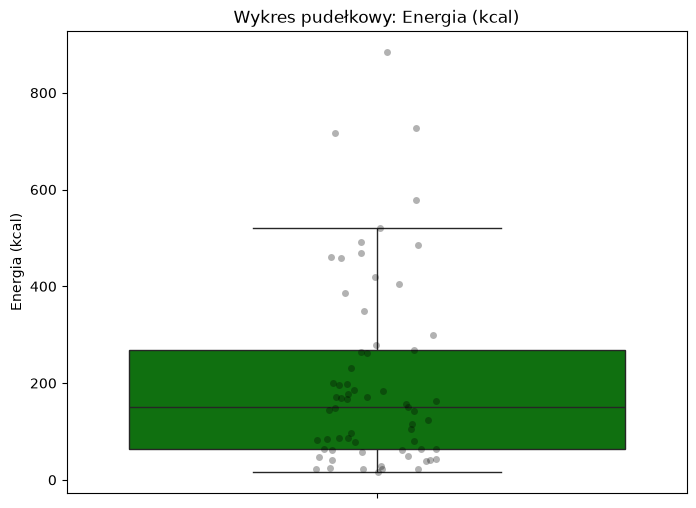

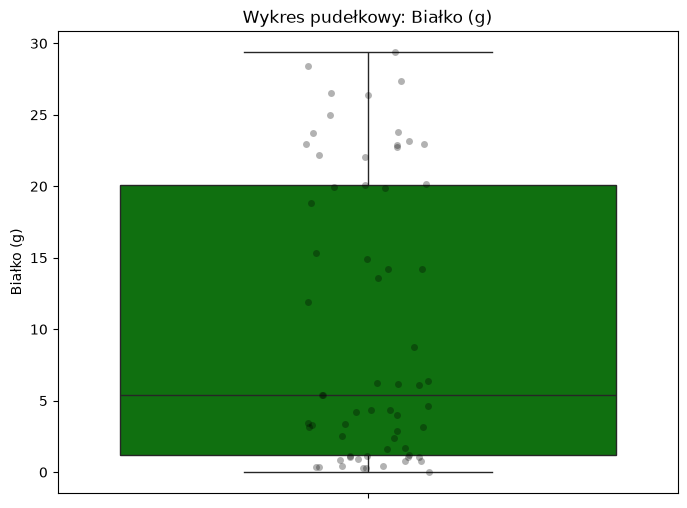

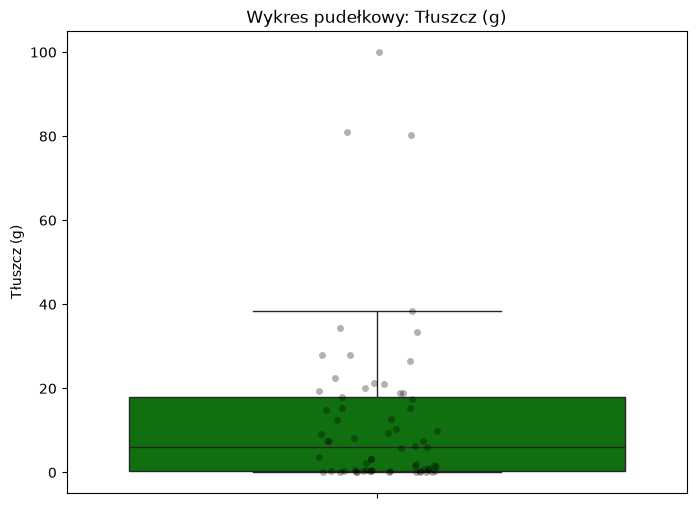

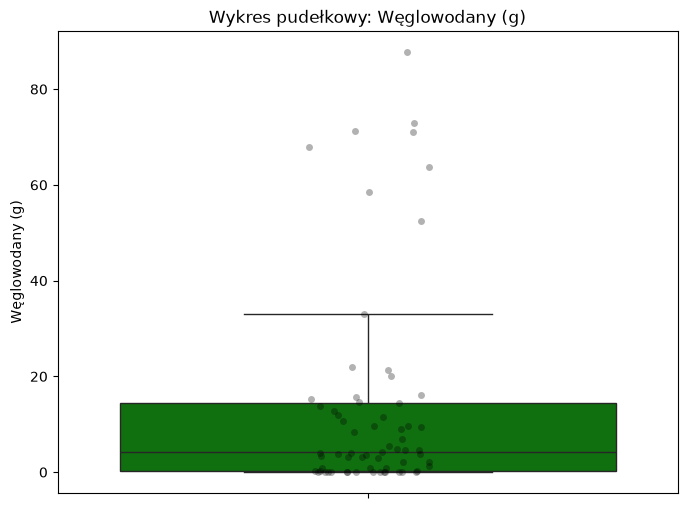

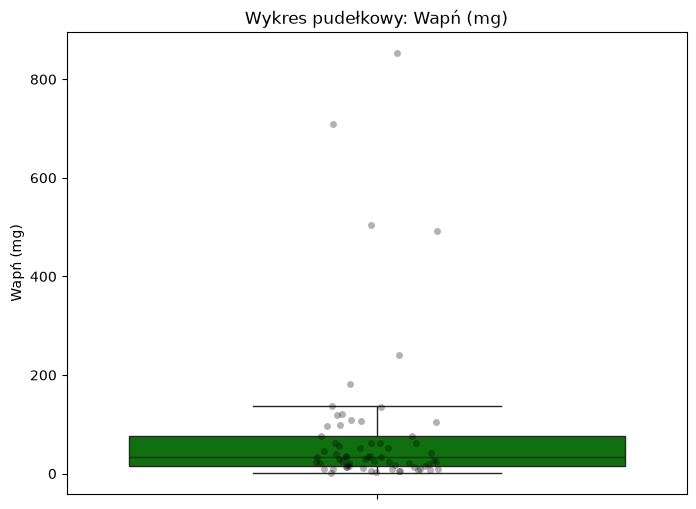

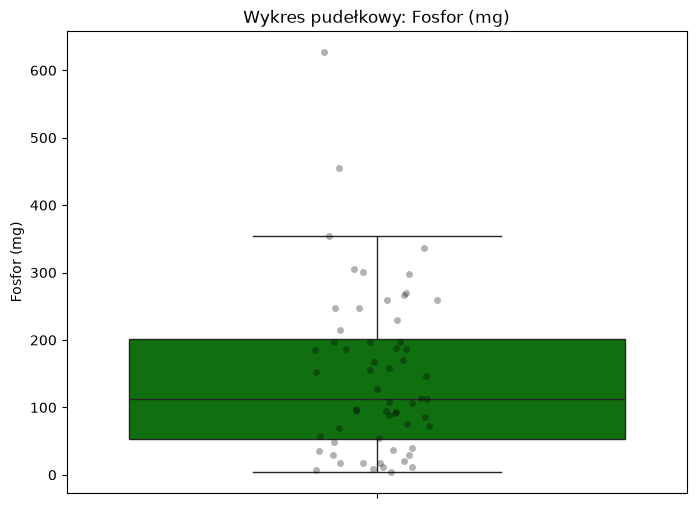

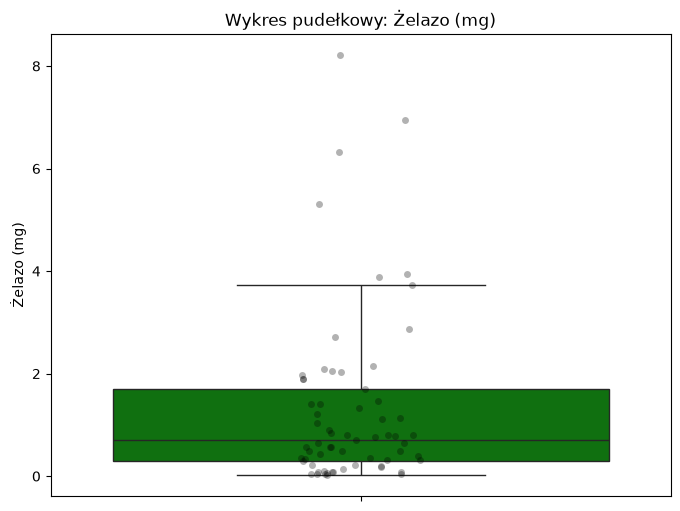

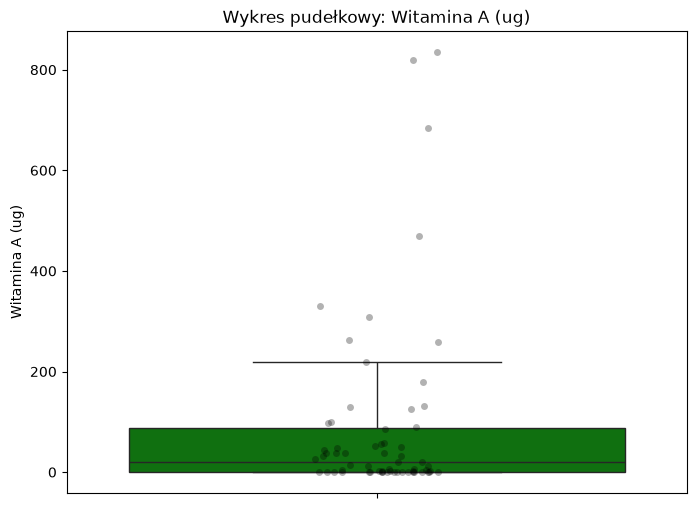

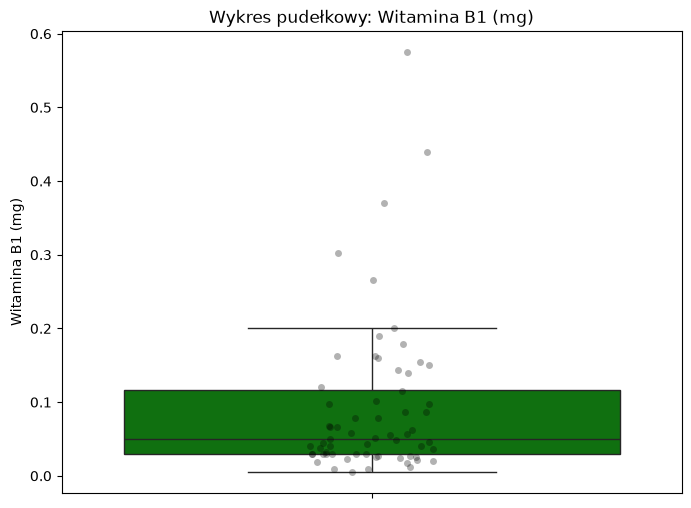

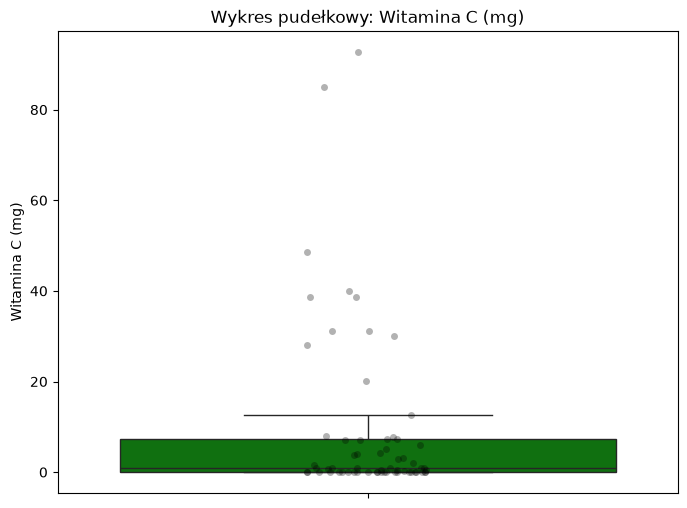

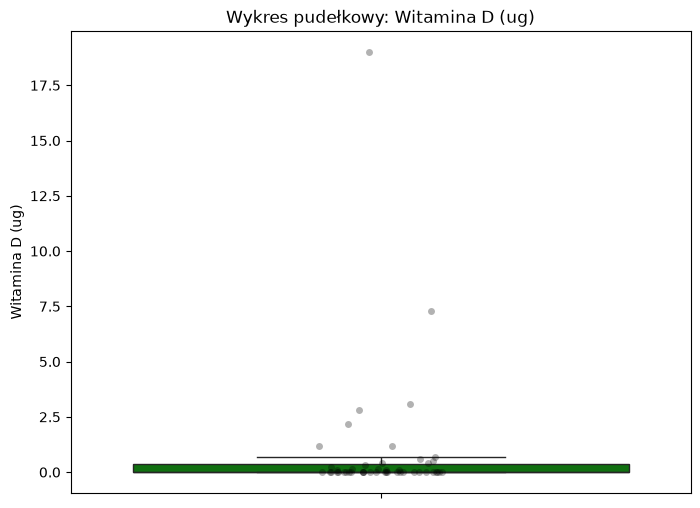

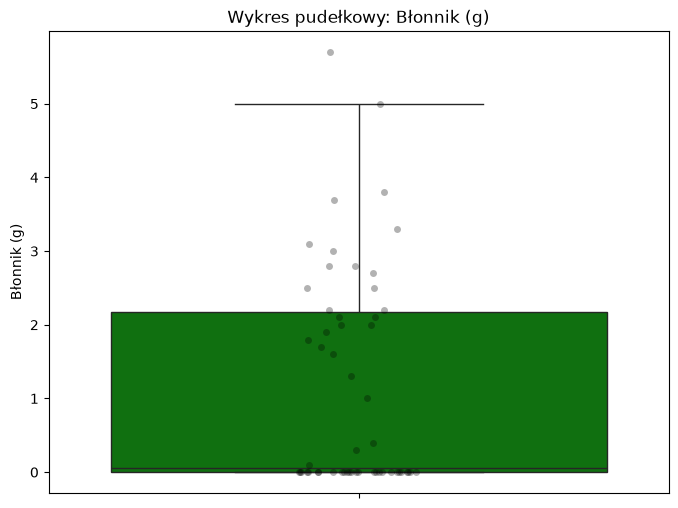

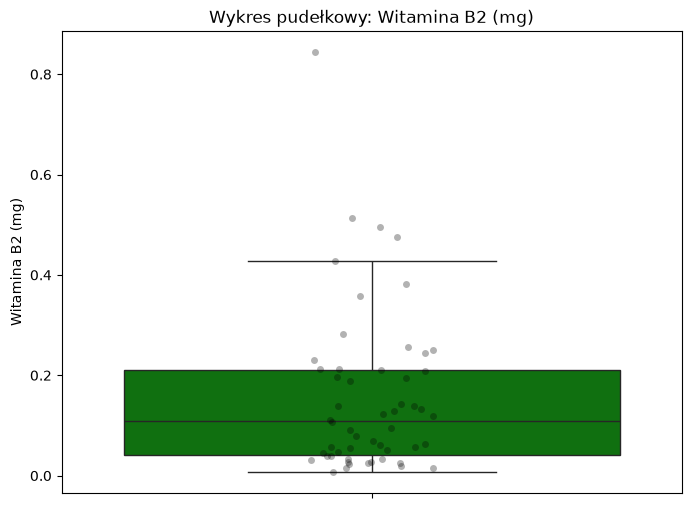

In [71]:
plot_box_strip(food_df,predictors)

In [72]:
# Podsumowanie podstwowych statystyk
food_df[predictors].describe()

,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
count,65.000000,65.000000,65.000000,65.000000,65.000000,60.000000,65.000000,63.000000,64.000000,62.000000,47.000000,54.000000,54.000000
mean,206.429671,10.122807,12.492926,13.785516,83.140843,147.323783,1.310656,91.857143,0.091697,9.391935,0.861984,1.177778,0.156705
std,194.581850,9.794732,19.447059,21.886636,155.580390,121.678867,1.702505,182.008052,0.105625,18.979707,2.971480,1.488531,0.162435
min,16.000000,0.000000,0.070000,0.000000,1.000000,4.000000,0.020000,0.000000,0.005000,0.000000,0.000000,0.000000,0.007000
25%,63.000000,1.180000,0.430000,0.300092,14.857143,52.750000,0.300000,0.000000,0.029000,0.000000,0.000000,0.000000,0.041500
50%,150.137255,5.400000,6.102059,4.110000,33.000000,113.000000,0.710000,20.000000,0.050544,0.900000,0.000000,0.050000,0.108500
75%,268.800000,20.080000,18.000000,14.450000,76.000000,201.500000,1.700000,88.000000,0.116500,7.350000,0.366867,2.175000,0.211500
max,884.000000,29.386667,100.000000,87.730000,853.000000,627.000000,8.212000,835.000000,0.575000,92.700000,19.000000,5.700000,0.844000


In [73]:
# graficzna analiza rozkładu zmiennej jakościowej
def plot_categorical_bars(df, categorical_vars):
    """
    Tworzy wykresy słupkowe dla każdej zmiennej jakościowej w podanej ramce danych.

    Parametry:
    - df: DataFrame zawierający zmienne jakościowe
    - categorical_vars: lista nazw kolumn zawierających zmienne jakościowe
    """
    for var in categorical_vars:
        plt.figure(figsize=(6, 4))
        df[var].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
        plt.title(f'Liczność kategorii dla zmiennej: {var}')
        plt.xlabel(var)
        plt.ylabel('Liczność')
        plt.xticks(rotation=45)  # Obrót etykiet kategorii dla czytelności
        plt.grid(axis='y', linestyle='--', alpha=0.7)
        plt.show()

... Ale w tym momencie nie mamy zmiennych jakościowych - nawyk warto wyrabiać!

In [74]:
# Tabela liczności dla zmiennych jakościowych

def categorical_summary(df, column):
    """
    Tworzy tabelę liczności dla jednej zmiennej jakościowej.
    
    Parametry:
    - df: DataFrame zawierający dane
    - column: nazwa kolumny jakościowej
    
    Zwraca:
    - DataFrame z licznością i procentowym udziałem kategorii
    """
    counts = df[column].value_counts(dropna=False)
    labels = counts.index.fillna("Brak danych").astype(str)
    percentages = (counts / counts.sum() * 100).round(2)
    
    return pd.DataFrame({"Etykieta": labels, "Liczność": counts.values, "Procent": percentages.values})

... Ale w tym momencie nie mamy zmiennych jakościowych

## Zrozumieliśmy dane teraz zaczynamy ich czyszczenie
### Na początek braki danych

1. Zmienne z niewielkim odsetkiem braków za pomocą mediany
2. Zmienne z większym odsetkiem za pomocą techniki KNN

In [75]:
# Uzupełnianie braków danych
# strategy='median' - braki uzupełniamy za pomocą mediany
simple_imputer= SimpleImputer(strategy='median')
food_df[missing_below_5]=simple_imputer.fit_transform(food_df[missing_below_5])

# n_neighbors=3 - do predykcji wykorzystujemy trzy najbliższe przypadki 
# weights='distance' - wpływ najbliższych przypadków jest odwrotnie proporcjonalny do ich odległości od analizowanego przypadku
knn_imputer= KNNImputer(n_neighbors=3,weights='distance')
food_df[predictors]= knn_imputer.fit_transform(food_df[predictors])

# upewniamy się czy braki zostały uzupełnione
null_report_3=food_df[predictors].isnull().mean().sort_values(ascending= False)
print(null_report_3)

Energia (kcal)      0.0
Białko (g)          0.0
Tłuszcz (g)         0.0
Węglowodany (g)     0.0
Wapń (mg)           0.0
Fosfor (mg)         0.0
Żelazo (mg)         0.0
Witamina A (ug)     0.0
Witamina B1 (mg)    0.0
Witamina C (mg)     0.0
Witamina D (ug)     0.0
Błonnik (g)         0.0
Witamina B2 (mg)    0.0
dtype: float64


### Kolejny krok to wartości odstające

1. Wartości spoza zakresu "obcinamy" do granic uznanych za typowe
2. Wartości ekstrematnie nietypowe być może będziemy musieli usunąć z analizy

In [76]:
# capping_method='iqr' - metoda oparta na rozstępie kwartylowym
# fold=1.5 - parametr sterujacy szerokocią przycinania 
import feature_engine.outliers
from feature_engine.outliers import Winsorizer

winsorizer = Winsorizer(capping_method='iqr', fold=1.5, tail='both')
food_df[predictors] = winsorizer.fit_transform(food_df[predictors])

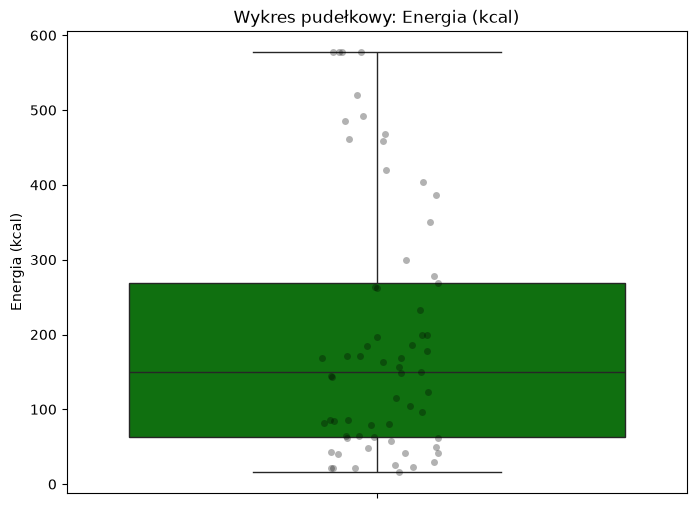

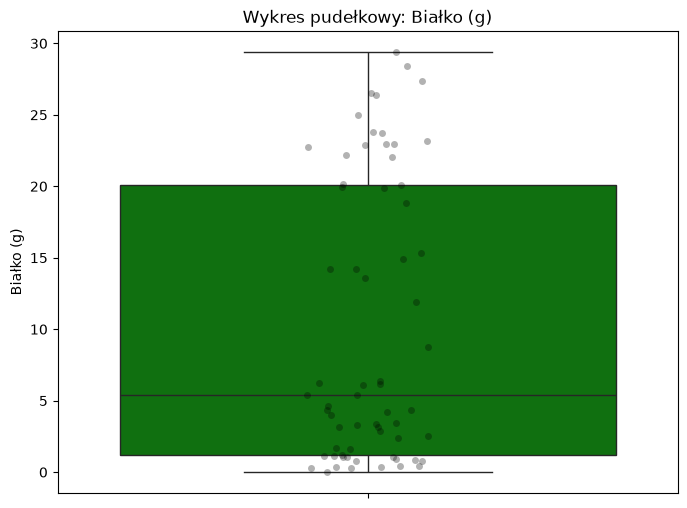

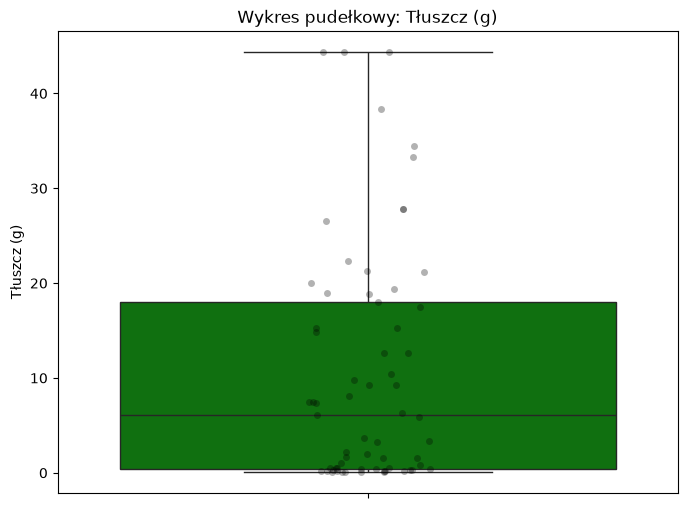

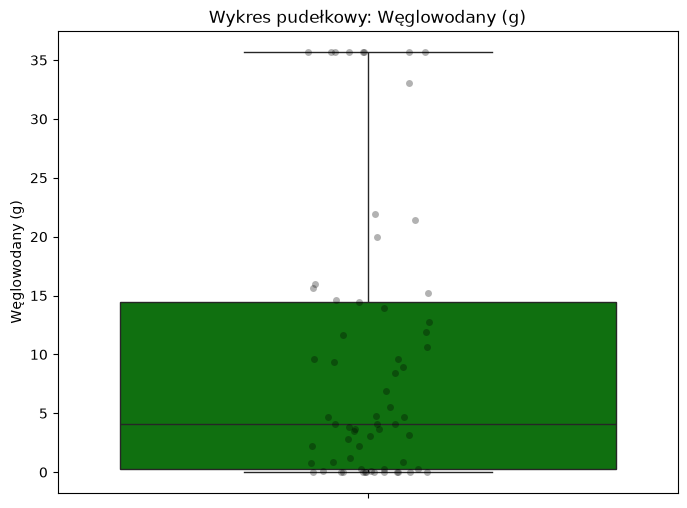

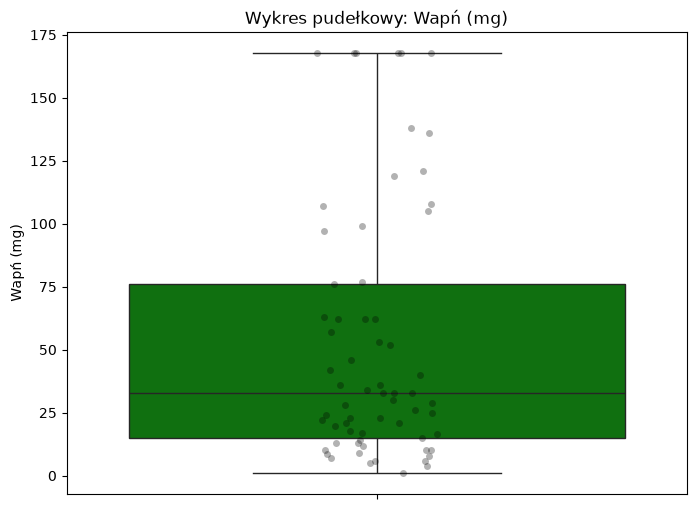

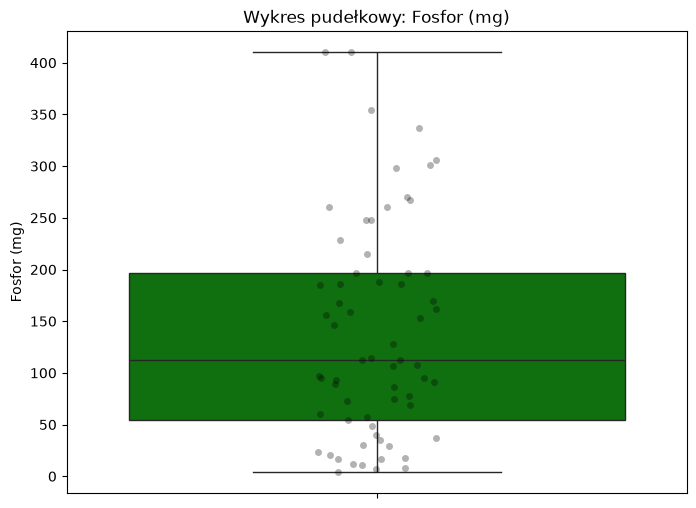

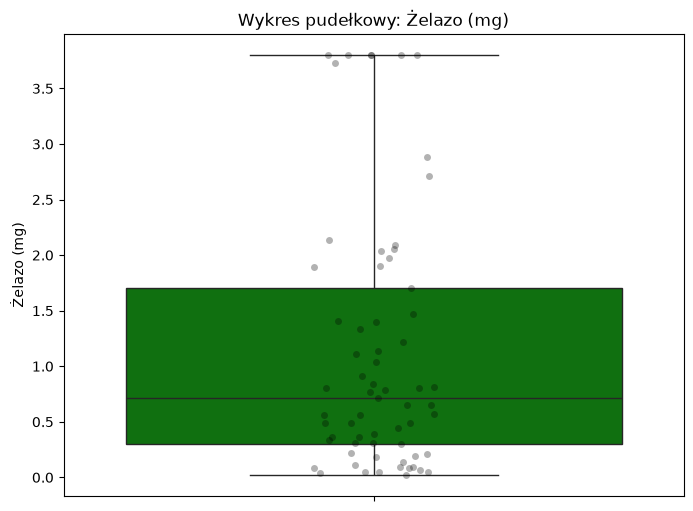

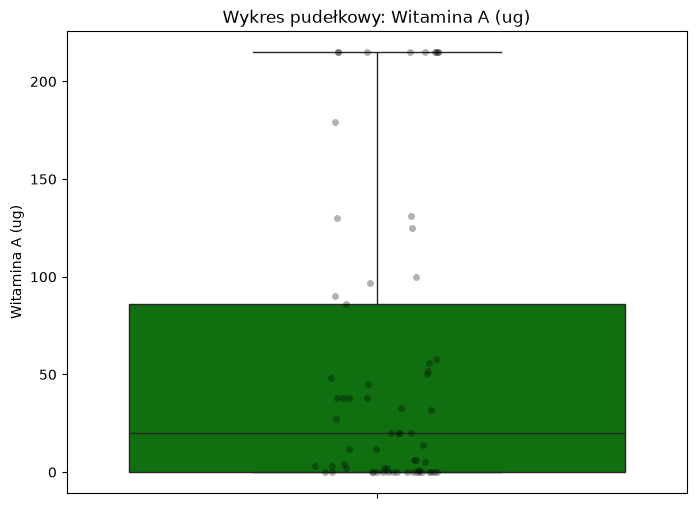

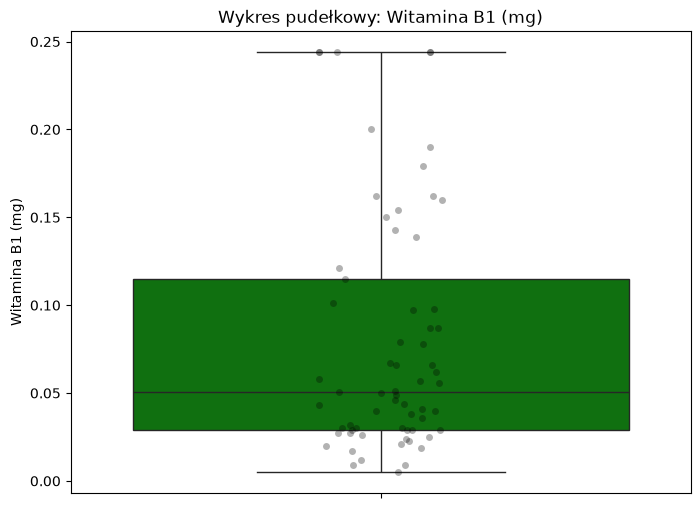

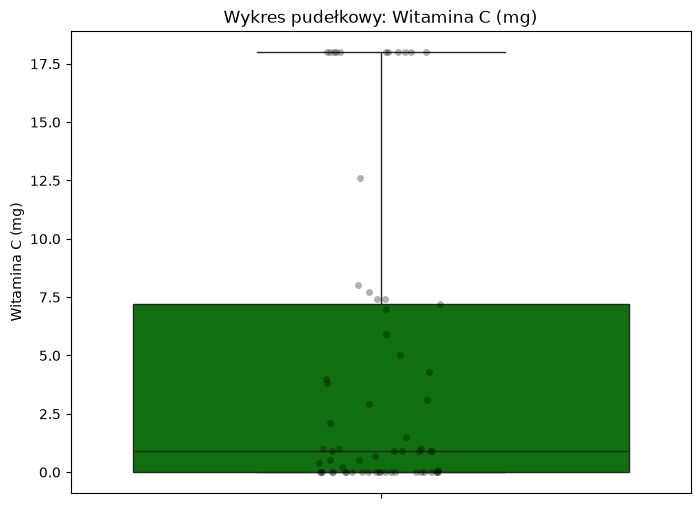

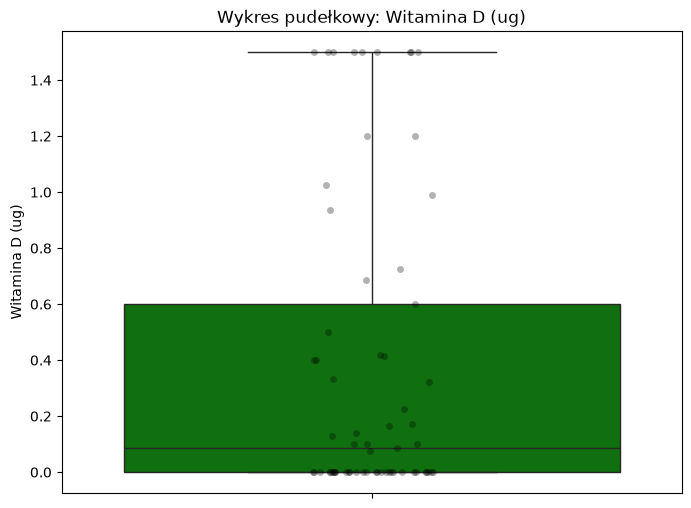

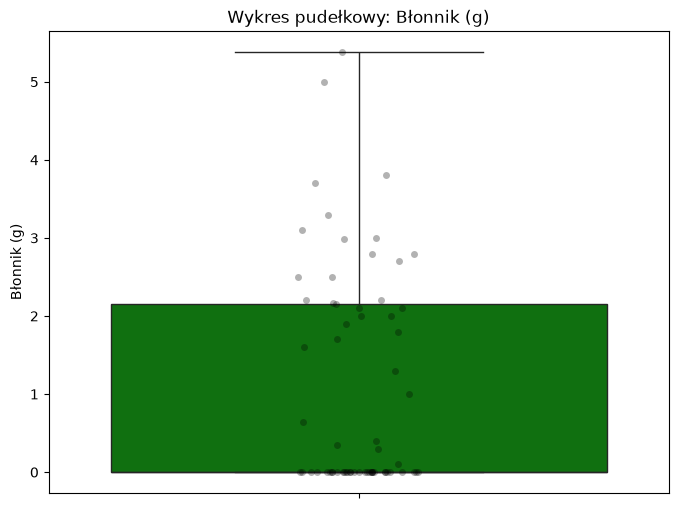

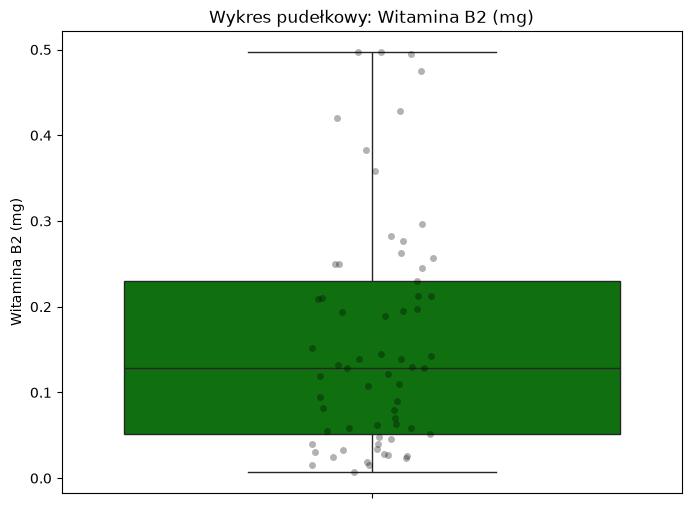

In [77]:
# Wykresy ramka-wąsy analiza pod kątem wartości odstających
plot_box_strip(food_df,predictors)

## Sprawdźmy powiązania pomiędzy zmiennymi

1. Korelacje między zmiennymi - za pomocą korelacji Spearmana
2. Graficzne przedstawienie za pomocą mapy ciepła
3. Powiązania pomiędzy zmiennymi za pomocą wykresu rozrzutu

In [78]:
# Obliczanie macierzy korelacji rang Spearmana
spearman_corr_matrix = food_df[predictors].corr(method='spearman')

spearman_corr_matrix.head(15)

,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
Energia (kcal),1.000000,0.368840,0.915020,0.000373,0.173933,0.558738,0.188796,0.086258,-0.071329,-0.735078,0.307367,-0.347880,0.410785
Białko (g),0.368840,1.000000,0.383197,-0.499357,0.197153,0.866297,0.518662,0.020996,0.282332,-0.440510,0.691088,-0.548094,0.727771
Tłuszcz (g),0.915020,0.383197,1.000000,-0.136946,0.309192,0.583465,0.157732,0.237116,-0.073172,-0.745210,0.377403,-0.411671,0.505300
Węglowodany (g),0.000373,-0.499357,-0.136946,1.000000,0.262279,-0.522945,-0.122021,-0.035821,-0.119997,0.309969,-0.684078,0.647069,-0.363161
Wapń (mg),0.173933,0.197153,0.309192,0.262279,1.000000,0.233798,0.057907,0.623478,0.000252,0.009130,0.108199,0.028285,0.264030
Fosfor (mg),0.558738,0.866297,0.583465,-0.522945,0.233798,1.000000,0.393939,0.135884,0.188310,-0.543722,0.709349,-0.649446,0.724470
Żelazo (mg),0.188796,0.518662,0.157732,-0.122021,0.057907,0.393939,1.000000,-0.149633,0.554648,-0.069697,0.123532,0.022961,0.460012
Witamina A (ug),0.086258,0.020996,0.237116,-0.035821,0.623478,0.135884,-0.149633,1.000000,-0.180226,0.053398,0.327542,-0.095391,0.147446
Witamina B1 (mg),-0.071329,0.282332,-0.073172,-0.119997,0.000252,0.188310,0.554648,-0.180226,1.000000,0.154910,-0.076594,0.062860,0.358586
Witamina C (mg),-0.735078,-0.440510,-0.745210,0.309969,0.009130,-0.543722,-0.069697,0.053398,0.154910,1.000000,-0.473471,0.569228,-0.464166


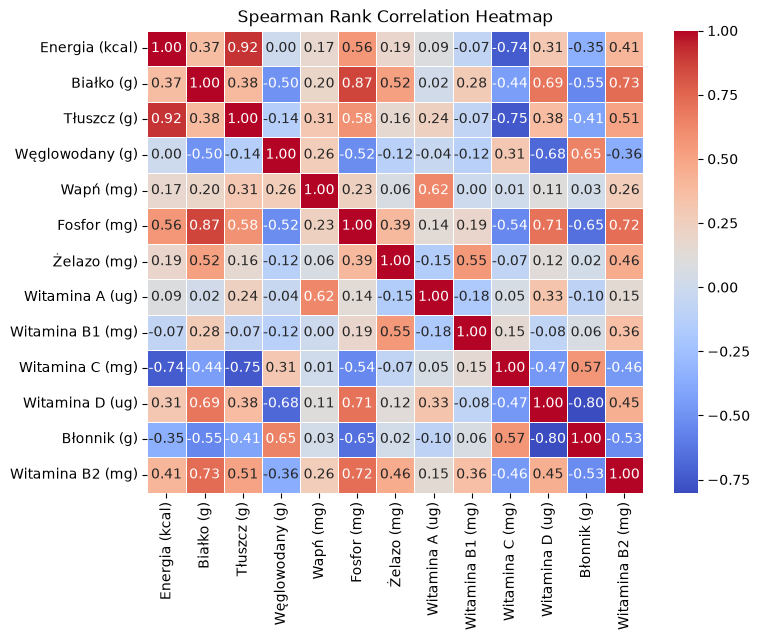

In [79]:
# Tworzenie mapy ciepła
plt.figure(figsize=(8, 6))
sns.heatmap(spearman_corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Tytuł wykresu
plt.title("Spearman Rank Correlation Heatmap")

# Wyświetlenie wykresu
plt.show()

### Zmienne Tłuszcz oraz Energia są wysoce skorelowane jedną z nich powinnośmy usunąć ze zbioru predyktorów

In [80]:
# W naszym przypadku wyeliminujemy ze zbioru danych zmienną Energia.
predictors = [var for var in predictors if var!='Energia (kcal)']

In [81]:
# Wykres rozrzutu
def scatter_plot(df, variables, hue=None):
    """
    Tworzy wykres rozrzutu dla podanych zmiennych.
    
    Parametry:
    - df: DataFrame z danymi
    - variables: lista 2 nazw kolumn (x, y)
    - hue: opcjonalna zmienna jakościowa do kolorowania punktów
    """
    if len(variables) != 2:
        raise ValueError("Lista 'variables' musi zawierać dokładnie 2 zmienne (x i y).")
    
    x, y = variables
    plt.figure(figsize=(8, 6))
    
    if hue:
        sns.scatterplot(data=df, x=x, y=y, hue=hue, palette="Set1", alpha=0.7)
        plt.legend(title=hue)
    else:
        sns.scatterplot(data=df, x=x, y=y, alpha=0.7)  # Bez hue i palette

    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(f'Wykres rozrzutu: {x} vs {y}')
    plt.show()

In [82]:
print(predictors)

['Białko (g)', 'Tłuszcz (g)', 'Węglowodany (g)', 'Wapń (mg)', 'Fosfor (mg)', 'Żelazo (mg)', 'Witamina A (ug)', 'Witamina B1 (mg)', 'Witamina C (mg)', 'Witamina D (ug)', 'Błonnik (g)', 'Witamina B2 (mg)']


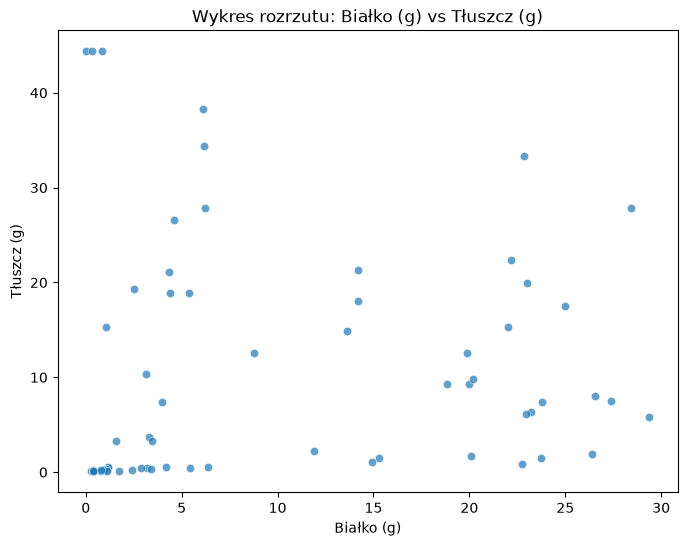

In [83]:
scatter_plot(food_df, ['Białko (g)', 'Tłuszcz (g)'])

### Analiza skupień wymaga przeskalowania danych do wspólnego zakresu
1. Wynik skalowania umieścimy w nowej ramce danych
2. Zobaczymy jak wyglądają rozkłady zmiennych po skalowaniu

In [84]:
# Skalujemy wartości predyktorów
# Przed wykonaniem skalowania wykonamy kopię ramki danych 
scaled_food_df = food_df.copy()

min_max_scaler = MinMaxScaler()
scaled_food_df[predictors]= min_max_scaler.fit_transform(scaled_food_df[predictors])

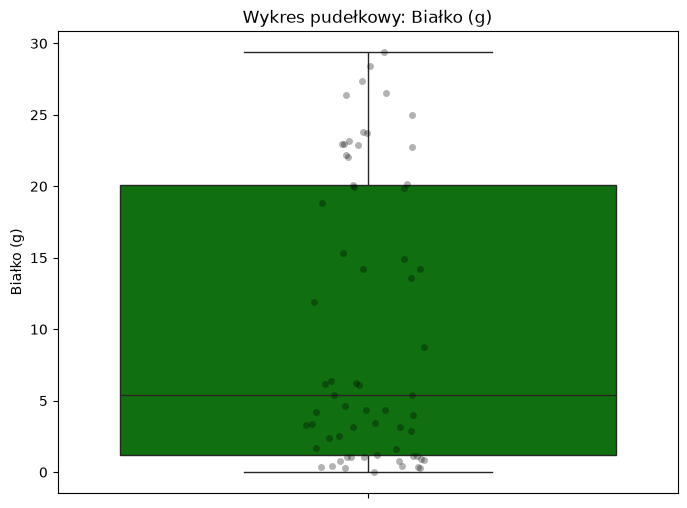

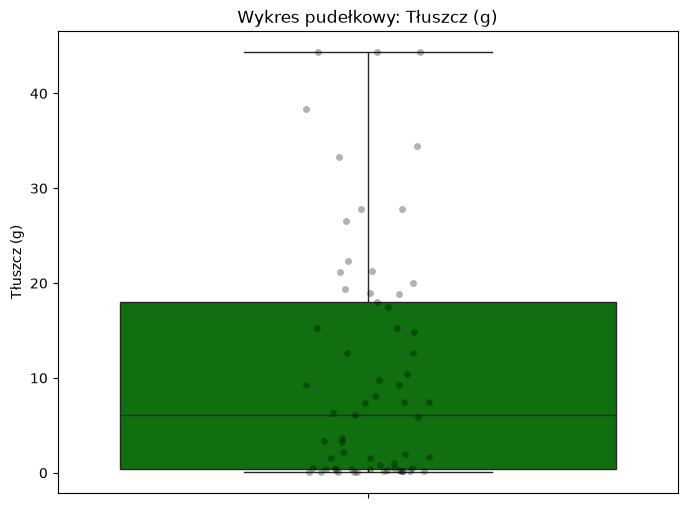

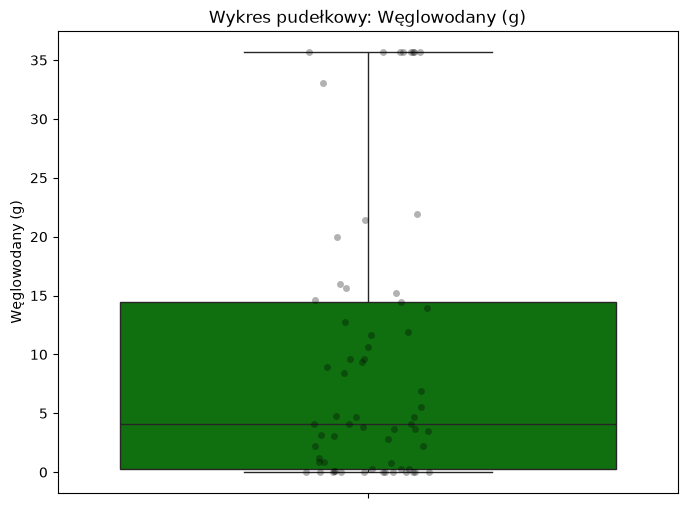

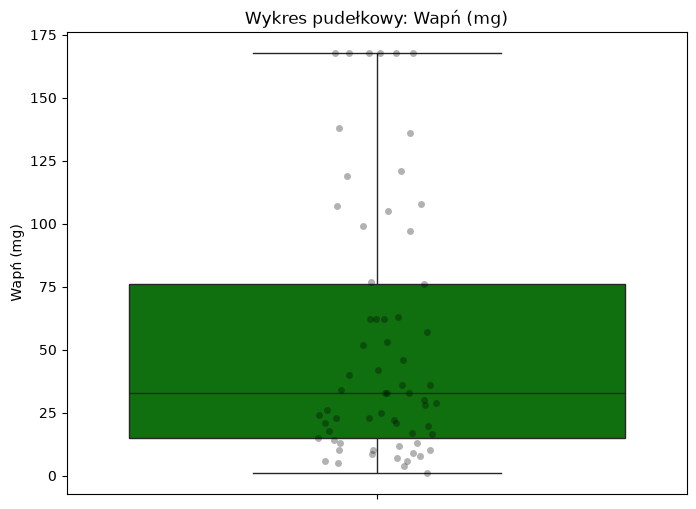

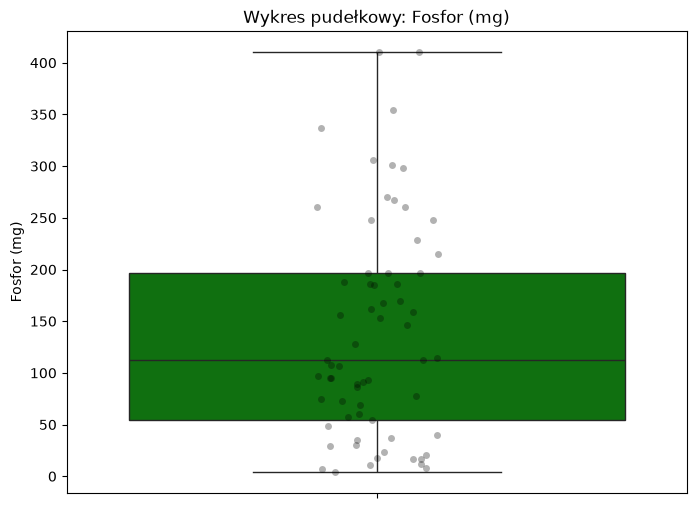

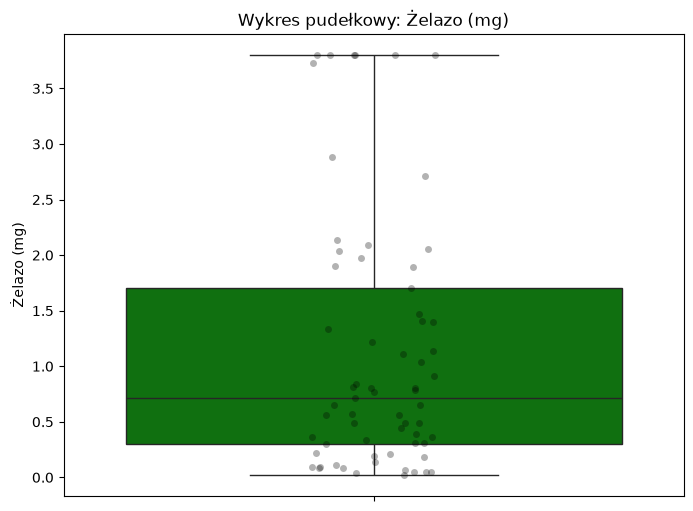

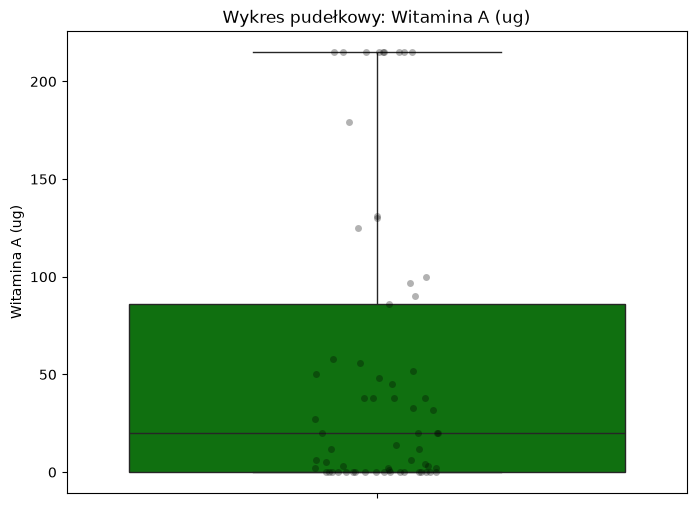

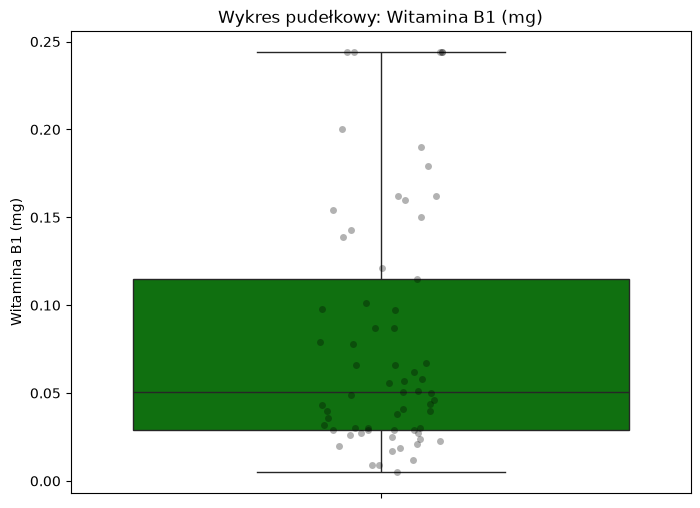

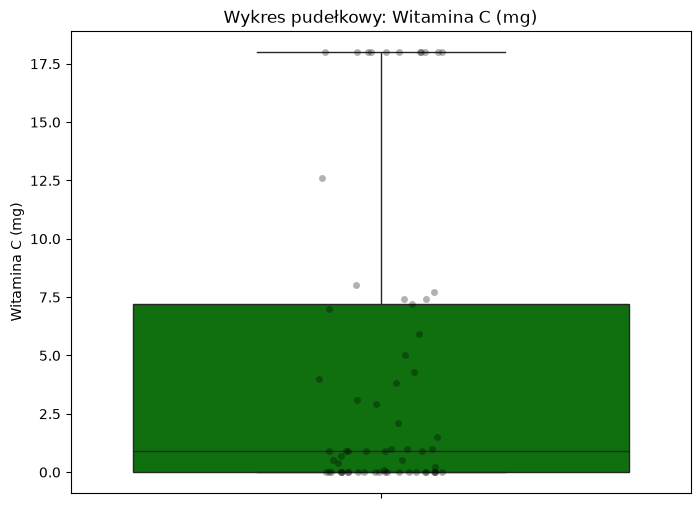

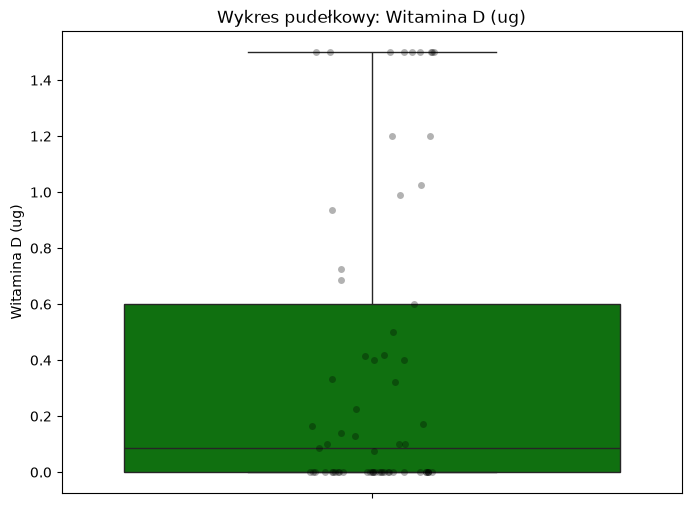

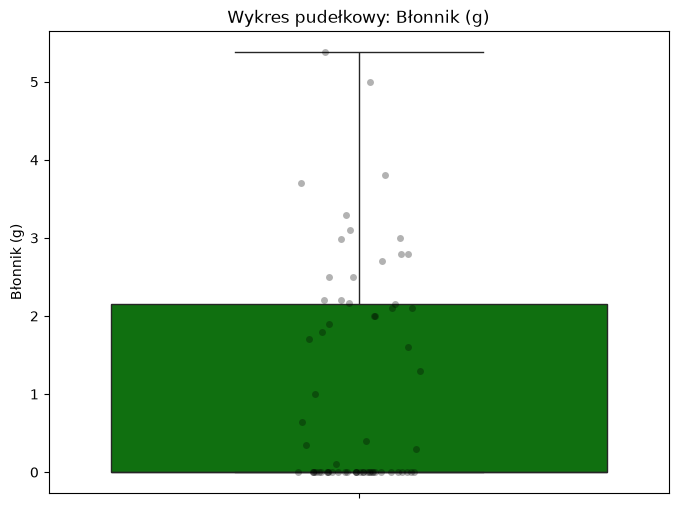

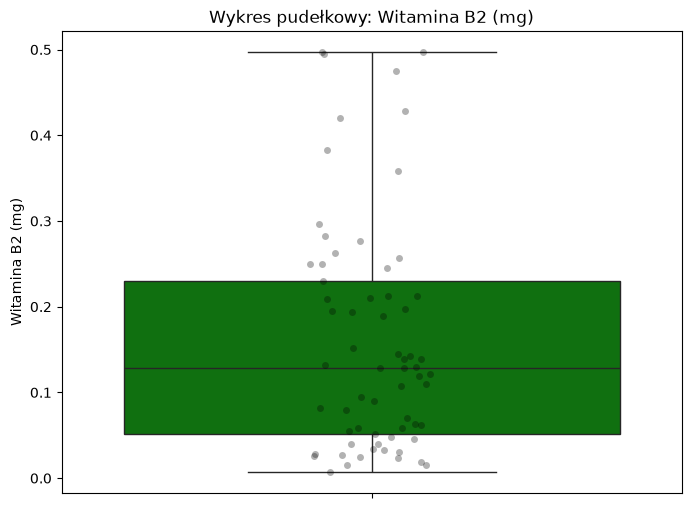

In [85]:
# Wykresy ramka-wąsy analiza pod kątem wartości odstających
plot_box_strip(food_df,predictors)

### Zbudujemy i ocenimy pierwszy model

Znamy już metodę ***k-średnich*** i sposób identyfikacji skupień za jej pomocą. W przypadku zbiorów o niewielkiej liczbie przypadków ciekawą alternatywą może być ***metoda aglomeracyjna***. 

In [86]:
import scipy.cluster.hierarchy as sch

def plot_dendrogram(df, variables, method='ward', figsize=(10, 6)):
    """
    Rysuje dendrogram dla hierarchicznego klastrowania.

    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista zmiennych do klastrowania
    - method: metoda łączenia klastrów ('ward', 'single', 'complete', 'average')
    - figsize: rozmiar wykresu (domyślnie (10, 6))
    """
    # Tworzenie macierzy połączeń (linkage matrix)
    linked = sch.linkage(df[variables], method=method)

    # Tworzenie wykresu
    plt.figure(figsize=figsize)
    sch.dendrogram(linked, orientation='top', distance_sort='ascending', show_leaf_counts=True)

    # Opis wykresu
    plt.title(f'Dendrogram (Metoda: {method})')
    plt.xlabel('Obiekty')
    plt.ylabel('Odległość')
    plt.show()

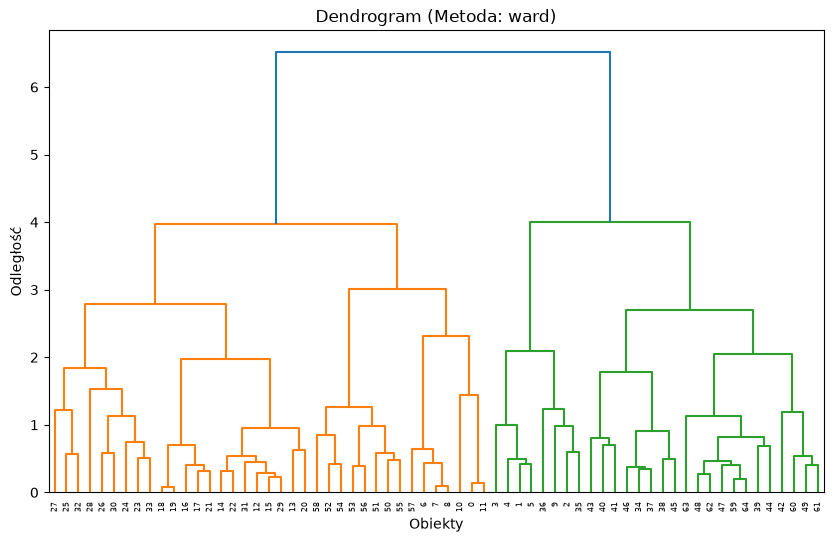

In [87]:
plot_dendrogram(scaled_food_df,predictors)

**W przypadku tej analizy jedną z metod określenia liczby skupień jest analiza wykresu przebiegu aglomeracji i identyfikacja pierwszego "wyraźnego" wzrostu liczby skupień**

In [88]:
def plot_agglomeration_process(df, variables, method='ward'):
    """
    Rysuje wykres przedstawiający przebieg aglomeracji.

    Parametry:
    - df: DataFrame zawierający dane
    - variables: lista nazw kolumn do klastrowania
    - method: metoda łączenia klastrów ('ward', 'single', 'complete', 'average')
    """
    # Macierz połączeń (linkage matrix)
    linked = sch.linkage(df[variables], method=method)

    # Pobranie numerów kroków i odpowiadających im odległości
    steps = np.arange(1, len(linked) + 1)  # Kolejne etapy klastrowania
    distances = linked[:, 2]  # Odległości wiązania

    # Tworzenie wykresu
    plt.figure(figsize=(10, 6))
    plt.plot(steps, distances, marker='o', linestyle='-', color='b', alpha=0.7, label='Odległość wiązania')

    # Opis osi i tytuł
    plt.xlabel("Krok")
    plt.ylabel("Odległość wiązania")
    plt.title(f"Wykres odległości wiązania względem etapów klastrowania ({method})")
    plt.legend()
    plt.grid(True)

    # Wyświetlenie wykresu
    plt.show()

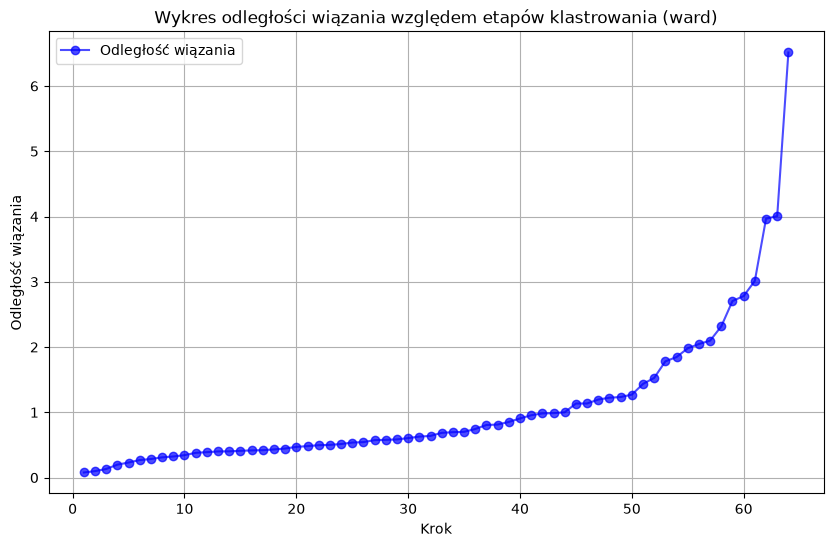

In [89]:
plot_agglomeration_process(scaled_food_df, predictors)

### Przykładowy kod dla metody aglomeracyjnej

In [90]:
from sklearn.cluster import AgglomerativeClustering

# Liczba klastrów
n_clusters = 4

agglo_model = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')

# Dopasowanie modelu i przypisanie klas
agglo_model_classes = agglo_model.fit_predict(scaled_food_df[predictors])

# Zapis predykcji do DataFrame
food_df['predicted_class'] = agglo_model_classes
scaled_food_df['predicted_class'] = agglo_model_classes

In [91]:
# Wyświetl pierwszych 10 rekordów
food_df.head(10) 

,ID,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg),predicted_class
Butter,1001,577.5,0.85,44.355,0.06,24.000000,112.841563,0.02,215.0,0.005,0.0,0.989836,0.000000,0.034000,0
"Cheese, cheddar",1009,404.0,22.87,33.310,3.09,167.714286,410.250000,0.14,215.0,0.029,0.0,0.600000,0.000000,0.428000,2
"Cheese, cream",1017,350.0,6.15,34.440,5.52,97.000000,107.000000,0.11,215.0,0.023,0.0,1.500000,0.000000,0.230000,2
"Cheese, feta",1019,264.0,14.21,21.280,4.09,167.714286,337.000000,0.65,125.0,0.154,0.0,0.400000,0.000000,0.497000,2
Mozzarella,1026,300.0,22.17,22.350,2.19,167.714286,354.000000,0.44,179.0,0.030,0.0,0.400000,0.000000,0.283000,2
Parmesan,1032,420.0,28.42,27.840,13.91,167.714286,410.250000,0.49,215.0,0.026,0.0,0.500000,0.000000,0.358000,2
Cream,1049,123.0,3.13,10.390,4.73,107.000000,95.000000,0.05,97.0,0.030,0.9,0.074876,0.000000,0.194000,0
Milk,1078,64.0,3.28,3.660,4.65,119.000000,93.000000,0.05,33.0,0.038,1.5,0.087967,0.347251,0.145155,0
Yogurt,1116,61.0,3.47,3.250,4.66,121.000000,95.000000,0.05,27.0,0.029,0.5,0.100000,0.000000,0.142000,0
Egg,1128,196.0,13.61,14.840,0.83,62.000000,215.000000,1.89,215.0,0.044,0.0,1.500000,0.000000,0.495000,2


### Chcemy teraz zrozumieć uzyskane wyniki

1. Oceniamy liczbę elementów w poszczególnych skupieniach (małe liczności mogą świadczyć o błędnym modelu)
2. Badamy średnie wartości zmiennych w skupieniach (brak zróżnicowania zmiennych może być podstawą do jej eliminacji)
3. Prezentujemy śerednie wartości wyskalowanych zmiennych na wykresie

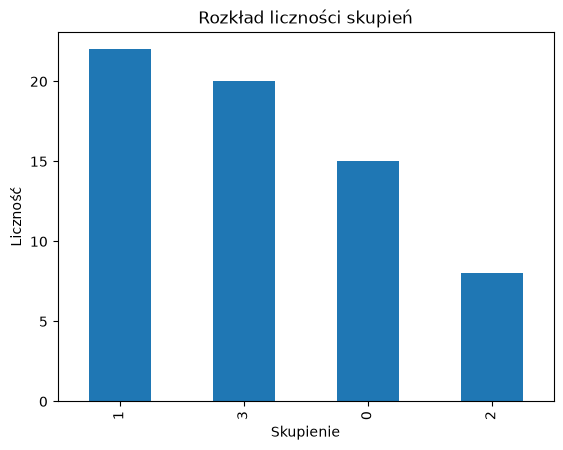

In [92]:
# Tworzenie wykresu słupkowego
food_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

In [93]:
# Grupowanie danych po segmencie (dane surowe) i obliczenie średnich
means = food_df.groupby("predicted_class")[predictors].mean()

means.head()

,Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
predicted_class,,,,,,,,,,,,
0,3.344667,22.144333,21.445926,69.933333,111.536113,0.846667,55.200000,0.046836,0.500000,0.152699,1.172074,0.112413
1,1.833636,0.959545,11.433636,36.759740,39.825787,0.703182,37.136364,0.091682,11.745455,0.000000,2.355454,0.068909
2,18.101250,22.295000,4.908750,134.321429,277.937500,0.872500,188.625000,0.047750,0.112500,0.987500,0.000000,0.330250
3,21.133124,7.602009,1.179426,24.757741,212.071350,1.911486,21.200000,0.104204,1.595000,0.737781,0.108547,0.229569


In [94]:
# Grupowanie danych po segmencie (dane wyskalowane) i obliczenie średnich
means_scaled = scaled_food_df.groupby("predicted_class")[predictors].mean()

means_scaled.head()

,Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg)
predicted_class,,,,,,,,,,,,
0,0.113816,0.498461,0.601150,0.413482,0.264704,0.218695,0.256744,0.175047,0.027778,0.101800,0.217865,0.215128
1,0.062397,0.020087,0.320496,0.214497,0.088187,0.180736,0.172727,0.362685,0.652525,0.000000,0.437832,0.126345
2,0.615968,0.501863,0.137597,0.799700,0.674308,0.225529,0.877326,0.178870,0.006250,0.658333,0.000000,0.659694
3,0.719140,0.170080,0.033060,0.142506,0.512176,0.500393,0.098605,0.415079,0.088611,0.491854,0.020177,0.454223


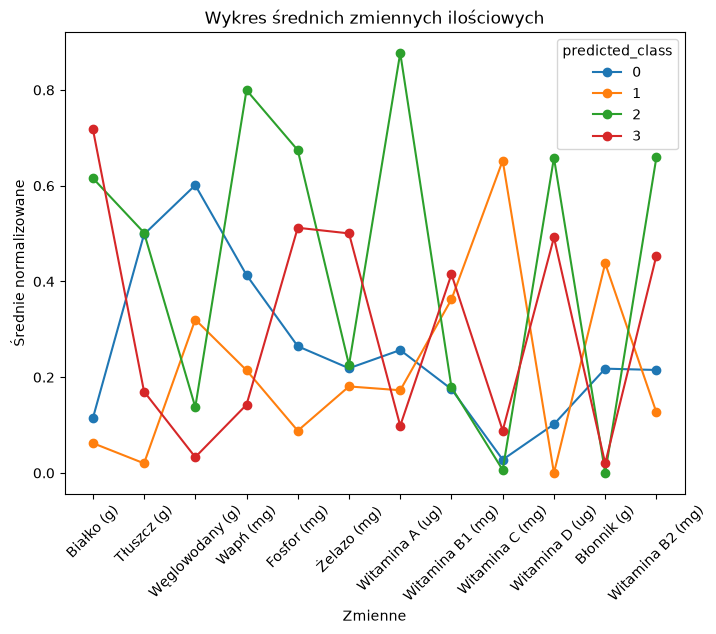

In [95]:
means_scaled.T.plot(marker="o", linestyle="-", figsize=(8, 6))

# Opisy osi i tytuł
plt.xlabel("Zmienne")
plt.ylabel("Średnie normalizowane")
plt.title("Wykres średnich zmiennych ilościowych")


# Wymuszenie wyświetlenia wszystkich etykiet i obrót
plt.xticks(ticks=range(len(means_scaled.T.index)), labels=means_scaled.T.index, rotation=45)

plt.show()

In [96]:
filtered_df = food_df[food_df["predicted_class"] == 3]

filtered_df.head(20)

,ID,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg),predicted_class
Codfish,15017,105.000000,22.760000,0.860000,0.000000,21.000000,260.000000,0.490000,14.0,0.087000,1.0,1.200000,0.000000,0.079000,3
Perch,15057,79.000000,15.310000,1.540000,0.000000,28.000000,248.000000,0.220000,12.0,0.040000,0.0,1.200000,0.000000,0.048000,3
Salmon,15082,184.000000,27.360000,7.500000,0.000000,46.000000,298.000000,0.710000,32.0,0.115000,1.0,1.500000,0.000000,0.249360,3
Tuna,15124,186.000000,26.530000,8.080000,0.000000,4.000000,267.000000,0.650000,5.0,0.017000,0.0,0.414277,0.000000,0.420586,3
Mussel,15164,86.000000,11.900000,2.240000,3.690000,26.000000,197.000000,3.800000,48.0,0.160000,8.0,1.500000,0.000000,0.210000,3
Octopus,15166,82.000000,14.910000,1.040000,2.200000,53.000000,186.000000,3.800000,45.0,0.030000,5.0,1.500000,0.000000,0.040000,3
Oyster,15168,199.000000,8.770000,12.580000,11.620000,62.000000,159.000000,3.800000,90.0,0.150000,3.8,0.164711,0.000000,0.262642,3
Crab,15227,115.000000,23.720000,1.510000,0.000000,33.000000,128.000000,2.880000,52.0,0.097000,7.2,1.027228,2.170932,0.082012,3
Lobster,15228,143.000000,26.410000,1.940000,3.120000,63.000000,229.000000,1.410000,6.0,0.009000,2.1,0.723910,0.000000,0.195220,3
Trout,15241,168.000000,23.800000,7.380000,0.000000,30.000000,270.000000,0.360000,100.0,0.143000,2.9,1.500000,0.000000,0.107000,3


W ramach pogłębionej interpretacji wyników możemy próbować identyfikować **"najbardziej typowego"** przedstawiciela swojej grupy. Tutaj pomocna może być informacja o odległości danego przypadku od środka skupienia. Najbardziej typoty przypadek - reprezentant skupienia to przypadek, który ma **najbliżej do środka** skupienia.

In [97]:
#potrzebujemy zatem funkcji obliczającej odległość od środka

def compute_distances_to_centroid(df, predictors, cluster_column):
    """
    Oblicza odległości każdego punktu od centroidu swojego klastra.

    Parametry:
    - df: DataFrame zawierający dane
    - predictors: lista nazw kolumn zmiennych ilościowych
    - cluster_column: nazwa kolumny z przypisanymi klastrami

    Zwraca:
    - Tablicę NumPy z odległościami do centroidów
    """
    # Obliczenie centroidów (średnich wartości w każdym klastrze)
    centroids = df.groupby(cluster_column)[predictors].mean()

    # Obliczanie odległości dla każdego wiersza
    distances = np.array([
        np.linalg.norm(df.loc[i, predictors] - centroids.loc[df.loc[i, cluster_column]])
        for i in df.index
    ])

    return distances

In [98]:
# Przykład użycia
distance_to_centroid = compute_distances_to_centroid(scaled_food_df, predictors, "predicted_class")

# Zapis wyników do DataFrame
scaled_food_df["distance_to_centroid"] = distance_to_centroid
food_df["distance_to_centroid"] = distance_to_centroid

Zobaczmy zatem jakie produkty są najbardziej typowe

In [99]:
filtered_df = food_df[food_df["predicted_class"] == 0]

# Sortowanie po kolumnie "distance_to_centroid" rosnąco
filtered_df = filtered_df.sort_values(by="distance_to_centroid", ascending=True)


filtered_df.head(1)

,ID,Energia (kcal),Białko (g),Tłuszcz (g),Węglowodany (g),Wapń (mg),Fosfor (mg),Żelazo (mg),Witamina A (ug),Witamina B1 (mg),Witamina C (mg),Witamina D (ug),Błonnik (g),Witamina B2 (mg),predicted_class,distance_to_centroid
"NESTLE, 100 GRAND Bar",19144,468.0,2.5,19.33,35.674862,76.0,86.0,0.34,38.0,0.058,0.7,0.0,1.0,0.119,0,0.455478


### Ocenimy teraz ten model pod kątem miar oraz za pomocą wykresów

1. Indeks sylwetki oraz wykres sylwetki
2. Dodatkowe miary
3. Wykresy PCA oraz t-SNE

### Spróbujmy ocenić model

1. Wskaźnik sylwetki
2. Wykres sylwetki

Blisko 1 → Bardzo dobre klastrowanie, obiekty dobrze dopasowane do swoich klastrów <BR>
Około 0.5 → Średnia jakość klastrowania, niektóre punkty mogą być źle przypisane <BR>
Blisko 0 → Punkty leżą na granicy klastrów, możliwe nakładanie się klas <BR>
Wartości ujemne → Punkty są przypisane do złych klastrów <BR>

In [100]:
from sklearn.metrics import silhouette_score

# Obliczenie wskaźnika sylwetki
silhouette_avg = silhouette_score(scaled_food_df[predictors], scaled_food_df["predicted_class"])

print(f"Wartość wskaźnika sylwetki: {silhouette_avg:.4f}")

Wartość wskaźnika sylwetki: 0.2663


In [101]:
from sklearn.metrics import silhouette_samples, silhouette_score

def plot_silhouette(data, cluster_column, predictors):
    """
    Tworzy wykres wskaźnika sylwetki dla danych po klasteryzacji.

    Parametry:
    - data: DataFrame zawierający przeskalowane zmienne predykcyjne oraz kolumnę z etykietami klastrów
    - cluster_column: nazwa kolumny zawierającej etykiety klas
    - predictors: lista nazw kolumn zawierających cechy używane do klasteryzacji
    """

    # Obliczenie wartości wskaźnika sylwetki dla każdego punktu
    silhouette_vals = silhouette_samples(data[predictors], data[cluster_column])

    # Pobranie unikalnych etykiet klas
    clusters = np.unique(data[cluster_column])

    # Tworzenie wykresu
    plt.figure(figsize=(8, 6))

    y_lower = 0
    for cluster in clusters:
        # Pobranie wartości sylwetki dla danego klastra
        cluster_vals = silhouette_vals[data[cluster_column] == cluster]
        cluster_vals.sort()

        y_upper = y_lower + len(cluster_vals)
        plt.fill_betweenx(np.arange(y_lower, y_upper), 0, cluster_vals, label=f"Skupienie {cluster}")

        y_lower = y_upper

    # Rysowanie średniego wskaźnika sylwetki jako pionowej linii
    silhouette_avg = silhouette_score(data[predictors], data[cluster_column])
    plt.axvline(x=silhouette_avg, color="red", linestyle="--", label="Średnia sylwetka")

    # Opisy osi i tytuł
    plt.xlabel("Wartość wskaźnika sylwetki")
    plt.ylabel("Obserwacje w skupieniach")
    plt.title("Wykres wskaźnika sylwetki dla skupień")

    # Legenda
    plt.legend()

    # Wyświetlenie wykresu
    plt.show()

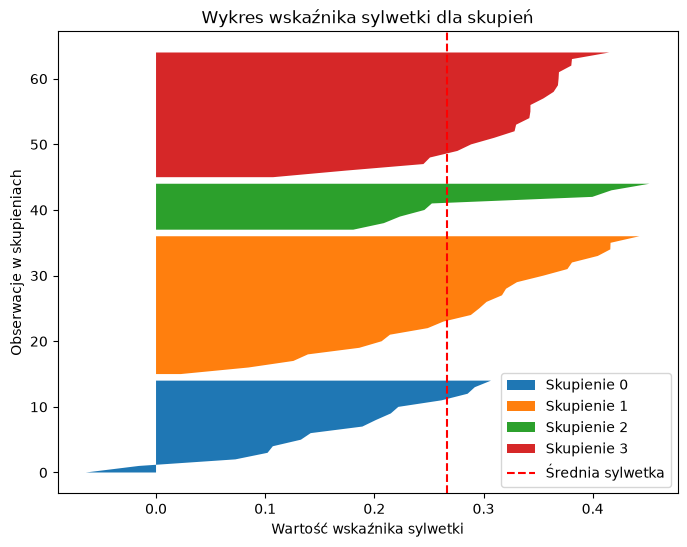

In [102]:
plot_silhouette(scaled_food_df,"predicted_class",predictors)

**Calinski-Harabasz Score (wartości większe = lepsze) – mierzy stosunek wariancji między klastrami do wariancji wewnątrz klastrów**

Jest to stosunek wariancji międzyklastrowej do wariancji wewnątrzklastrowej. ***Brak uniwersalnych progów*** ale w praktyce:<BR>
* ≥ 500 – bardzo dobrze oddzielone klastry (dla dużych zbiorów danych).
* 100-500 – dobra klasteryzacja.
* < 100 – klastry są słabo oddzielone.
* Bliskie 0 – bardzo słaba klasteryzacja, przypomina losowy podział.

**Davies-Bouldin Score (wartości niższe = lepsze) – mierzy, jak bardzo klastry są od siebie oddzielone** Interpretacja:
* Blisko 0 – bardzo dobrze oddzielone klastry.
* 0.5 – 1.5 – dobra jakość klastrów.
* \> 2 – klastry zaczynają się nakładać i są źle rozdzielone.
* \> 3 – bardzo słaba klasteryzacja.

Wartość bliska 0 oznacza dobrze oddzielone klastry. Jednak dla różnych zbiorów danych różne wartości mogą być uznawane za dobre.     
    

In [103]:
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score

# Obliczenie wskaźników
calinski_harabasz = calinski_harabasz_score(scaled_food_df[predictors], scaled_food_df["predicted_class"])
davies_bouldin = davies_bouldin_score(scaled_food_df[predictors], scaled_food_df["predicted_class"])

# Wyświetlenie wyników
print(f"Wartość wskaźnika Calinskiego-Harabasza: {calinski_harabasz:.4f}")
print(f"Wartość wskaźnika Daviesa-Bouldina: {davies_bouldin:.4f}")

Wartość wskaźnika Calinskiego-Harabasza: 19.7368
Wartość wskaźnika Daviesa-Bouldina: 1.4412


### Wizualizacja i ocena jakości segmentacji

Po przeprowadzeniu segmentacji chcemy sprawdzić, czy nasze grupy są dobrze rozdzielone. Ponieważ mamy wiele cech, trudno to zobaczyć bezpośrednio, dlatego stosujemy redukcję wymiarów – PCA (analiza głównych składowych) lub t-SNE. Te metody pozwalają nam przedstawić dane na wykresie 2D, zachowując jak najwięcej informacji o strukturze klastrów. Jeśli klastry są dobrze oddzielone, oznacza to, że segmentacja przebiegła poprawnie i rzeczywiście znaleźliśmy grupy o różnych cechach.

In [104]:
def visualize_clusters(df, predictors, cluster_col, method='PCA'):
    """
    Wizualizuje klastry w 2D przy użyciu PCA lub t-SNE, dodając centroidy.
    
    Parametry:
    - df: DataFrame zawierający dane
    - predictors: lista kolumn do redukcji wymiarów
    - cluster_col: nazwa kolumny zawierającej przypisane klastry
    - method: 'PCA' lub 't-SNE' (domyślnie 'PCA')
    """
    
    # Redukcja wymiarów
    if method == 'PCA':
        reducer = PCA(n_components=2)
        x_label, y_label, title = "Pierwsza składowa PCA", "Druga składowa PCA", "Klastry w PCA"
    elif method == 't-SNE':
        reducer = TSNE(n_components=2, perplexity=30, random_state=42)
        x_label, y_label, title = "Pierwszy wymiar t-SNE", "Drugi wymiar t-SNE", "Klastry w t-SNE"
    else:
        raise ValueError("Metoda musi być 'PCA' lub 't-SNE'")
    
    # Przekształcenie danych
    X_transformed = reducer.fit_transform(df[predictors])
    
    # Dodanie centroidów – obliczamy średnie wartości dla każdego klastra
    df_transformed = df.copy()
    df_transformed['X1'] = X_transformed[:, 0]
    df_transformed['X2'] = X_transformed[:, 1]
    
    centroids = df_transformed.groupby(cluster_col)[['X1', 'X2']].mean()
    
    # Tworzenie wykresu
    plt.figure(figsize=(6, 5))
    sns.scatterplot(x='X1', y='X2', hue=cluster_col, palette='Set1', data=df_transformed, alpha=0.7)
    
    # Dodanie centroidów jako czarnych "X"
    plt.scatter(centroids['X1'], centroids['X2'], marker="X", s=200, c="black", label="Centroidy")
    
    # Opisy wykresu
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.legend(title="Skupienie")
    plt.show()

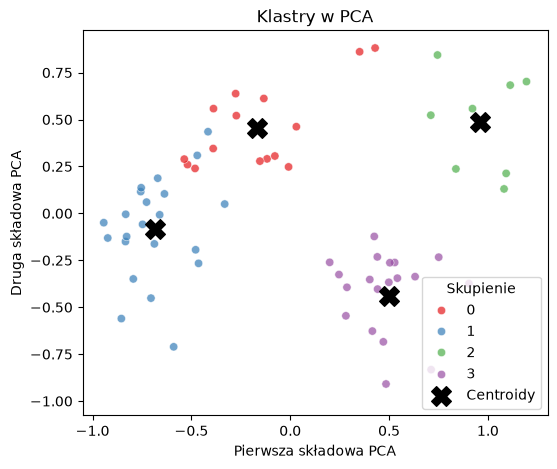

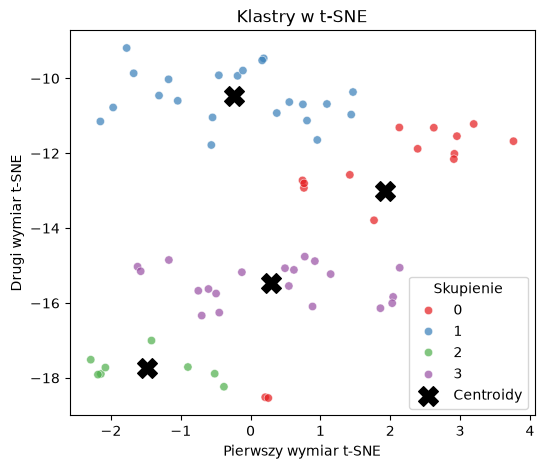

In [105]:
visualize_clusters(scaled_food_df, predictors, 'predicted_class', method='PCA')
visualize_clusters(scaled_food_df, predictors, 'predicted_class', method='t-SNE')

### Czy możemy obliczyć wystandaryzowany wskaźnik Randa? Nie! Nie mamy rzeczywistej grupy produktów

### Co jeszcze można zrobić? Zbudujemy model innymi metodami

1. W modelu k-średnich podajemy z góry liczbę skupień - przyjmijmy  że są 4 skupienia
2. Sieci neuronowe Kohonena - przyjmujemy, że mamy 4 skupienia
3. Metoda GMM - przyjmujemy że mamy 4 skupienia
4. DBSCAN - nie możemy tego założyć

* Budujemy model i od razu przypisujemy do kolumny z danymi predykcję modelu
* Predykcję zapisujemy zarówno do oryginalnych danych jak i do przeskalowanych danych
* Oceniamy model znanymi sposobami

* **Możemy porównać zgodność modeli za pomocą  wskaźnika Randa!**

### Metoda K-średnich

In [106]:
# Metoda K-średnich
from sklearn.cluster import KMeans
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

# Algorytm k-średnich
#podaj liczbę skupień
n_clusters= 4
seed = 42
kmeans_model = KMeans(n_clusters=n_clusters, random_state=seed)

#wykonaj model i przypisz predykcję do tablicy z wynikami
kmeans_model_classes = kmeans_model.fit_predict(scaled_food_df[predictors])

# zapisz predykcję do kolumny w ramce danych
food_df['predicted_class'] = kmeans_model_classes

# zapisz predykcję do kolumny w ramce danych wystandaryzowanych
scaled_food_df['predicted_class'] = kmeans_model_classes


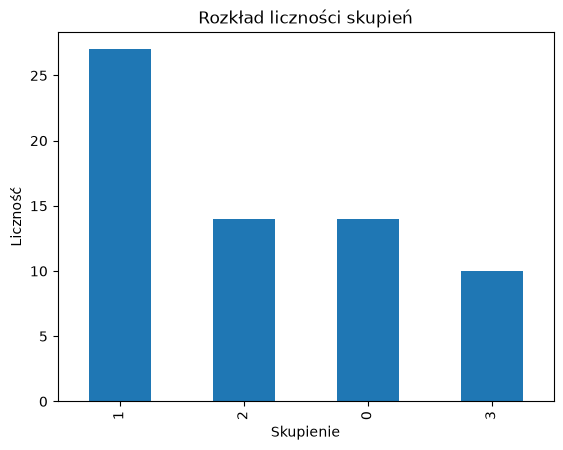

In [107]:
# Tworzenie wykresu słupkowego
food_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

### Metoda GMM

In [108]:
#Metoda GMM
import warnings
warnings.simplefilter("ignore", category=UserWarning)

from sklearn.mixture import GaussianMixture

# Liczba klastrów (analogicznie do K-Means)
n_clusters = 4

gmm_model = GaussianMixture(n_components=n_clusters, random_state=seed)

# Dopasowanie modelu i przypisanie klas
gmm_model_classes = gmm_model.fit_predict(scaled_food_df[predictors])

# Zapis predykcji do DataFrame
food_df['predicted_class'] = gmm_model_classes
scaled_food_df['predicted_class'] = gmm_model_classes

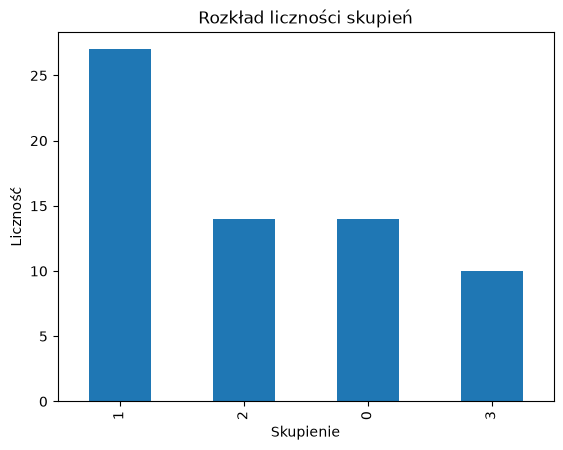

In [109]:
# Tworzenie wykresu słupkowego
food_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

### Sieci neuronowe Kohonena

In [110]:
from minisom import MiniSom

# Parametry SOM
map_size = (1, 4)  # Rozmiar siatki (np. 5x5)
input_len = len(predictors)  # Liczba zmiennych wejściowych
sigma = 1.0  # Promień sąsiedztwa
learning_rate = 0.5  # Tempo uczenia

# Inicjalizacja i trenowanie SOM
som = MiniSom(map_size[0], map_size[1], input_len, sigma=sigma, learning_rate=learning_rate, random_seed=seed)
som.random_weights_init(scaled_food_df[predictors].values)
som.train_random(scaled_food_df[predictors].values, num_iteration=1000)

# Przypisanie klastrów do obserwacji
winner_nodes = np.array([som.winner(x) for x in scaled_food_df[predictors].values])  # Współrzędne najlepszych neuronów
cluster_labels = np.ravel_multi_index(winner_nodes.T, dims=map_size)  # Zamiana współrzędnych na jedną etykietę klastra

# Zapis predykcji do DataFrame
food_df['predicted_class'] = cluster_labels
scaled_food_df['predicted_class'] = cluster_labels


# Wizualizacja wyników
#plt.figure(figsize=(6, 6))
#plt.scatter(winner_nodes[:, 0], winner_nodes[:, 1], c=cluster_labels, cmap="viridis", edgecolors='k')
#plt.colorbar(label="Numer klastra")
#plt.title("Analiza skupień za pomocą Sieci Kohonena")
#plt.xlabel("Współrzędna X")
#plt.ylabel("Współrzędna Y")
#plt.grid()
#plt.show()


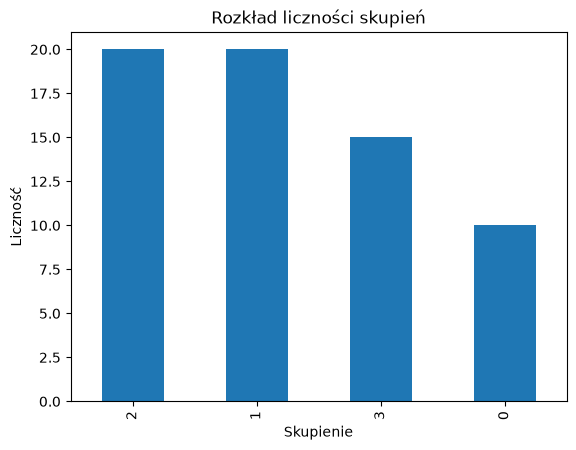

In [111]:
# Tworzenie wykresu słupkowego
food_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

### Metoda DBSCAN

Działanie algorytmu jest wrażliwe na wartość "eps"!

In [112]:
from sklearn.cluster import DBSCAN

# Parametry DBSCAN
eps = 0.99  # Maksymalna odległość do sąsiada w klastrze
min_samples = 5  # Minimalna liczba punktów do utworzenia klastra

dbscan_model = DBSCAN(eps=eps, min_samples=min_samples)

# Wykonaj model i przypisz predykcję do tablicy z wynikami
dbscan_model_classes = dbscan_model.fit_predict(scaled_food_df[predictors])

# Zapisz predykcję do kolumny w ramce danych
food_df['predicted_class'] = dbscan_model_classes

# Zapisz predykcję do kolumny w ramce danych wystandaryzowanych
scaled_food_df['predicted_class'] = dbscan_model_classes

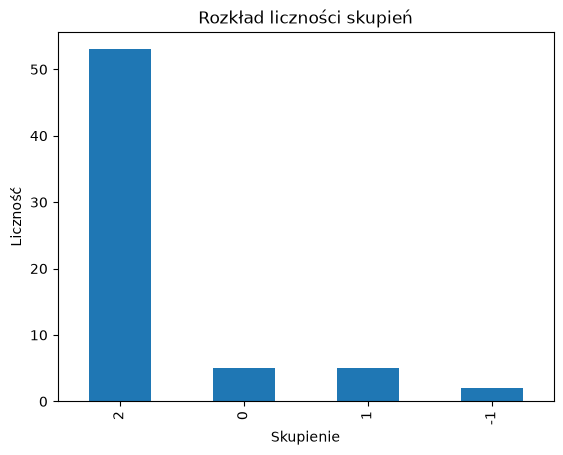

In [113]:
# Tworzenie wykresu słupkowego
food_df["predicted_class"].value_counts().plot(kind="bar")

# Opisy osi i tytuł
plt.xlabel("Skupienie")
plt.ylabel("Liczność")
plt.title("Rozkład liczności skupień")

# Wyświetlenie wykresu
plt.show()

### Być może inna liczba skupień pozwoliłaby uzyskać lepszy wynik?

1. Zbudujemy wiele modeli dla różnych wartości k
2. Wynik porównamy za pomocą wykresu osypiska dla wartości inercji
3. Sprawdzimy też wartości indeksu sylwetki

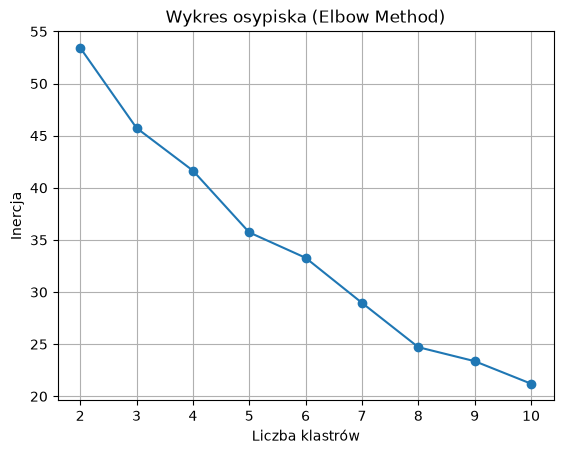

,Liczba skupień,Wskaźnik sylwetki
0,2,0.271294
1,3,0.233528
2,4,0.216347
3,5,0.234180
4,6,0.234652
5,7,0.245909
6,8,0.250359
7,9,0.242184
8,10,0.252557


In [114]:
# Zakres liczby skupień
cluster_range = range(2, 11)

# Listy do zapisania wyników
inertia_values = []
silhouette_values = []

# Pętla dla różnej liczby skupień
for k in cluster_range:
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(scaled_food_df[predictors])
    
    inertia_values.append(model.inertia_)
    silhouette_values.append(silhouette_score(scaled_food_df[predictors], labels))
    

# Wykres osypiska (Elbow Method)
plt.plot(cluster_range, inertia_values, marker="o", linestyle="-")
plt.xlabel("Liczba klastrów")
plt.ylabel("Inercja")
plt.title("Wykres osypiska (Elbow Method)")
plt.grid(True)
plt.show()

# Tabelka wskaźników sylwetki
df_silhouette = pd.DataFrame({"Liczba skupień": cluster_range, "Wskaźnik sylwetki": silhouette_values})
df_silhouette.head(10)

### Co jeszcze można zrobić?

1. Zmienne pochodne
2. Eliminacja zmiennych nadmiernie skorelowanych
3. Inne ustawienia metod
4. A może nasz model jest wystarczająco dobry?